# Import Libraries

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
from pathlib import Path
import json

from sklearn.feature_selection import mutual_info_classif
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from keras import callbacks

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from sklearn.compose import ColumnTransformer
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

keras.utils.set_random_seed(42)

import warnings
warnings.filterwarnings("ignore")

# Load Dataset

In [2]:
PROJECT_ROOT = Path(".").resolve().parent 

DATA_DIR   = PROJECT_ROOT / "Data"  
ASSET_DIR  = PROJECT_ROOT / "Assets" 
MODEL_DIR  = PROJECT_ROOT / "Models"   

df = pd.read_csv(DATA_DIR / "diabetes_012_health_indicators_BRFSS2015_BRFSS2021.csv")

In [3]:
df.head()
df1 = df.copy()
df2 = df.copy()
df3 = df.copy()

# Dataset Overview

In [4]:
df.head(10)

,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Year,Health_Status,Health_Status_Label
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,18.0,15.0,1.0,0.0,9.0,4.0,3.0,2015,0,Healthy
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,7.0,6.0,1.0,2015,0,Healthy
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,30.0,30.0,1.0,0.0,9.0,4.0,8.0,2015,0,Healthy
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,0.0,0.0,0.0,0.0,11.0,3.0,6.0,2015,0,Healthy
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,3.0,0.0,0.0,0.0,11.0,5.0,4.0,2015,0,Healthy
5,0.0,1.0,1.0,1.0,25.0,1.0,0.0,0.0,1.0,1.0,...,0.0,2.0,0.0,1.0,10.0,6.0,8.0,2015,0,Healthy
6,0.0,1.0,0.0,1.0,30.0,1.0,0.0,0.0,0.0,0.0,...,0.0,14.0,0.0,0.0,9.0,6.0,7.0,2015,0,Healthy
7,0.0,1.0,1.0,1.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,11.0,4.0,4.0,2015,0,Healthy
8,2.0,1.0,1.0,1.0,30.0,1.0,0.0,1.0,0.0,1.0,...,30.0,30.0,1.0,0.0,9.0,5.0,1.0,2015,1,At Risk
9,0.0,0.0,0.0,1.0,24.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,8.0,4.0,3.0,2015,0,Healthy


In [5]:
df.tail(10)

,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Year,Health_Status,Health_Status_Label
453321,0.0,0.0,1.0,1.0,36.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,1.0,8.0,6.0,8.0,2021,0,Healthy
453322,2.0,1.0,1.0,1.0,33.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,1.0,10.0,4.0,5.0,2021,1,At Risk
453323,0.0,0.0,0.0,1.0,19.0,0.0,0.0,0.0,1.0,1.0,...,0.0,0.0,0.0,1.0,10.0,4.0,1.0,2021,0,Healthy
453324,0.0,1.0,1.0,0.0,21.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,1.0,8.0,4.0,5.0,2021,0,Healthy
453325,0.0,0.0,0.0,1.0,29.0,0.0,0.0,0.0,1.0,1.0,...,0.0,5.0,0.0,1.0,2.0,6.0,11.0,2021,0,Healthy
453326,2.0,1.0,1.0,1.0,21.0,0.0,0.0,0.0,1.0,1.0,...,0.0,0.0,0.0,1.0,10.0,2.0,3.0,2021,1,At Risk
453327,0.0,1.0,0.0,1.0,25.0,1.0,0.0,0.0,1.0,1.0,...,20.0,0.0,0.0,0.0,3.0,4.0,5.0,2021,0,Healthy
453328,0.0,0.0,1.0,1.0,31.0,0.0,0.0,0.0,1.0,1.0,...,0.0,0.0,0.0,1.0,7.0,6.0,10.0,2021,0,Healthy
453329,0.0,1.0,0.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,0.0,0.0,0.0,1.0,10.0,4.0,6.0,2021,0,Healthy
453330,0.0,0.0,1.0,1.0,32.0,0.0,0.0,0.0,1.0,0.0,...,2.0,2.0,0.0,0.0,6.0,6.0,6.0,2021,0,Healthy


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 453331 entries, 0 to 453330
Data columns (total 25 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_012          453331 non-null  float64
 1   HighBP                453331 non-null  float64
 2   HighChol              453331 non-null  float64
 3   CholCheck             453331 non-null  float64
 4   BMI                   453331 non-null  float64
 5   Smoker                453331 non-null  float64
 6   Stroke                453331 non-null  float64
 7   HeartDiseaseorAttack  453331 non-null  float64
 8   PhysActivity          453331 non-null  float64
 9   Fruits                453331 non-null  float64
 10  Veggies               453331 non-null  float64
 11  HvyAlcoholConsump     453331 non-null  float64
 12  AnyHealthcare         453331 non-null  float64
 13  NoDocbcCost           453331 non-null  float64
 14  GenHlth               453331 non-null  float64
 15  

In [7]:
df.shape

(453331, 25)

# Statistical Summary

In [8]:
df.describe()

,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Year,Health_Status
count,453331.000000,453331.000000,453331.000000,453331.000000,453331.000000,453331.000000,453331.000000,453331.000000,453331.000000,453331.000000,...,453331.000000,453331.000000,453331.000000,453331.000000,453331.000000,453331.000000,453331.000000,453331.000000,453331.000000,453331.000000
mean,0.324765,0.443191,0.426565,0.960506,28.905870,0.446054,0.042962,0.097231,0.750013,0.610466,...,2.564475,3.825029,4.324604,0.174226,0.457339,7.980143,5.041497,6.355292,2017.958765,0.173679
std,0.722126,0.496763,0.494578,0.194768,6.719965,0.497082,0.202772,0.296273,0.433006,0.487645,...,1.047625,7.888508,8.754169,0.379304,0.498177,3.177301,0.974903,2.286781,2.999720,0.378833
min,0.000000,0.000000,0.000000,0.000000,12.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,2015.000000,0.000000
25%,0.000000,0.000000,0.000000,1.000000,24.000000,0.000000,0.000000,0.000000,1.000000,0.000000,...,2.000000,0.000000,0.000000,0.000000,0.000000,6.000000,4.000000,5.000000,2015.000000,0.000000
50%,0.000000,0.000000,0.000000,1.000000,28.000000,0.000000,0.000000,0.000000,1.000000,1.000000,...,2.000000,0.000000,0.000000,0.000000,0.000000,8.000000,5.000000,7.000000,2015.000000,0.000000
75%,0.000000,1.000000,1.000000,1.000000,32.000000,1.000000,0.000000,0.000000,1.000000,1.000000,...,3.000000,3.000000,3.000000,0.000000,1.000000,10.000000,6.000000,8.000000,2021.000000,0.000000
max,2.000000,1.000000,1.000000,1.000000,99.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,5.000000,30.000000,30.000000,1.000000,1.000000,13.000000,6.000000,11.000000,2021.000000,1.000000


In [9]:
print(df.isnull().sum())
df = df.dropna()

Diabetes_012            0
HighBP                  0
HighChol                0
CholCheck               0
BMI                     0
Smoker                  0
Stroke                  0
HeartDiseaseorAttack    0
PhysActivity            0
Fruits                  0
Veggies                 0
HvyAlcoholConsump       0
AnyHealthcare           0
NoDocbcCost             0
GenHlth                 0
MentHlth                0
PhysHlth                0
DiffWalk                0
Sex                     0
Age                     0
Education               0
Income                  0
Year                    0
Health_Status           0
Health_Status_Label     0
dtype: int64


In [10]:
print(df.duplicated().sum())
df = df.drop_duplicates()

0


In [11]:
for col in df.columns :
    print(df[col].value_counts(), end = "\n\n")

Diabetes_012
0.0    374597
2.0     68492
1.0     10242
Name: count, dtype: int64

HighBP
0.0    252419
1.0    200912
Name: count, dtype: int64

HighChol
0.0    259956
1.0    193375
Name: count, dtype: int64

CholCheck
1.0    435427
0.0     17904
Name: count, dtype: int64

BMI
27.0    41496
26.0    34208
24.0    31990
28.0    29208
25.0    28346
        ...  
99.0        2
94.0        2
80.0        2
91.0        2
96.0        1
Name: count, Length: 86, dtype: int64

Smoker
0.0    251121
1.0    202210
Name: count, dtype: int64

Stroke
0.0    433855
1.0     19476
Name: count, dtype: int64

HeartDiseaseorAttack
0.0    409253
1.0     44078
Name: count, dtype: int64

PhysActivity
1.0    340004
0.0    113327
Name: count, dtype: int64

Fruits
1.0    276743
0.0    176588
Name: count, dtype: int64

Veggies
1.0    365716
0.0     87615
Name: count, dtype: int64

HvyAlcoholConsump
0.0    424793
1.0     28538
Name: count, dtype: int64

AnyHealthcare
1.0    432105
0.0     21226
Name: count, dtype: in

# Numerical Features Distribution

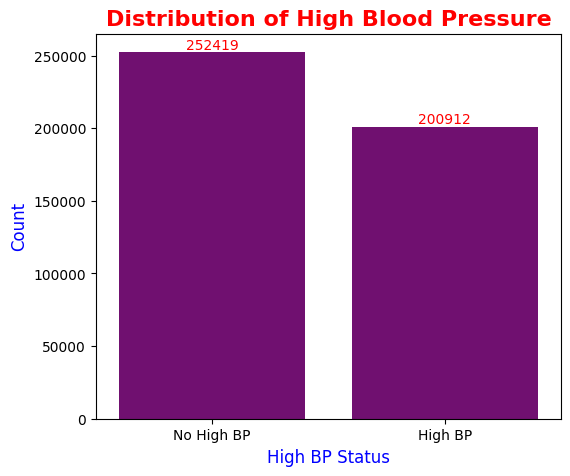

In [12]:
df["HighBP_Label"] = df["HighBP"].map({0.0: "No High BP", 1.0: "High BP"})

plt.figure(figsize=(6, 5))
ax = sns.countplot(
    x=df.HighBP_Label, order=["No High BP", "High BP"], color="purple"
)
for i in ax.containers:
  ax.bar_label(i, color="red")

plt.title(
    "Distribution of High Blood Pressure", fontsize=16, fontweight="bold", color="red"
)
plt.xlabel("High BP Status", fontsize=12, color="blue")
plt.ylabel("Count", fontsize=12, color="blue")

plt.savefig(ASSET_DIR / "HighBP.png", dpi=300, bbox_inches="tight")
plt.show()

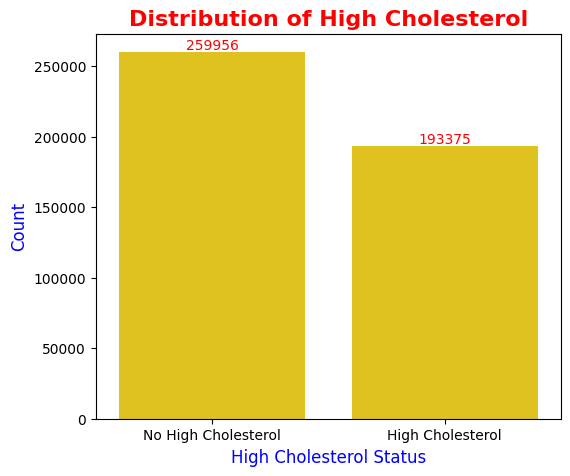

In [13]:
df["HighChol_Label"] = df["HighChol"].map({
    0.0: "No High Cholesterol",
    1.0: "High Cholesterol",
})

plt.figure(figsize=(6, 5))
ax = sns.countplot(
    x=df.HighChol_Label,
    order=["No High Cholesterol", "High Cholesterol"],
    color="gold",
)
for i in ax.containers:
  ax.bar_label(i, color="red")

plt.title(
    "Distribution of High Cholesterol", fontsize=16, fontweight="bold", color="red"
)
plt.xlabel("High Cholesterol Status", fontsize=12, color="blue")
plt.ylabel("Count", fontsize=12, color="blue")

plt.savefig(ASSET_DIR / "HighChol.png", dpi=300, bbox_inches="tight")
plt.show()

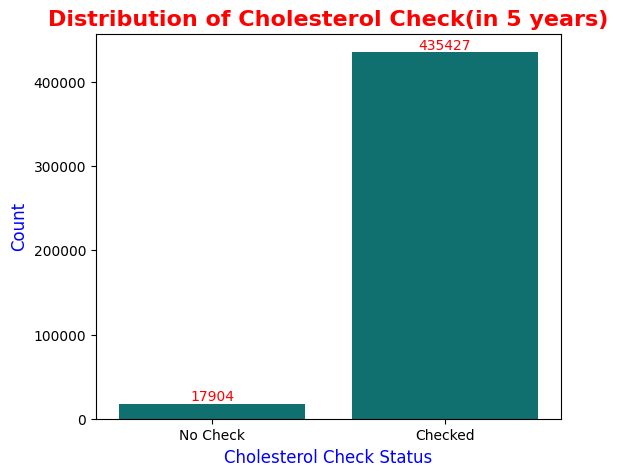

In [14]:
df["CholCheck_Label"] = df["CholCheck"].map({0.0: "No Check", 1.0: "Checked"})

plt.figure(figsize=(6, 5))
ax = sns.countplot(x=df.CholCheck_Label, order=["No Check", "Checked"], color="teal")
for i in ax.containers:
  ax.bar_label(i, color="red")

plt.title(
    "Distribution of Cholesterol Check(in 5 years)", fontsize=16, fontweight="bold", color="red"
)
plt.xlabel("Cholesterol Check Status", fontsize=12, color="blue")
plt.ylabel("Count", fontsize=12, color="blue")

plt.savefig(ASSET_DIR / "CholCheck.png", dpi=300, bbox_inches="tight")
plt.show()

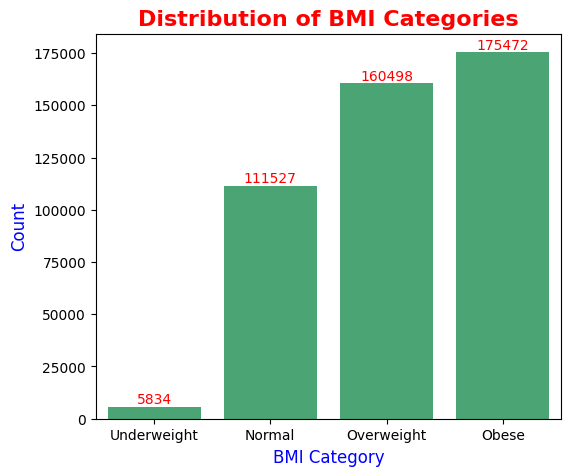

In [15]:
# bins = [0, 18.5, 24.9, 29.9, 100]
# labels = ['Underweight', 'Normal', 'Overweight', 'Obese']
# df['BMICat'] = pd.cut(df.BMI, bins=bins, labels=labels)

bins = [0, 18.5, 25.0, 30.0, float('inf')]
labels = ['Underweight', 'Normal', 'Overweight', 'Obese']
df['BMICat'] = pd.cut(df.BMI, bins=bins, labels=labels, right=False)

plt.figure(figsize=(6, 5))
ax = sns.countplot(x=df.BMICat, color="mediumseagreen")  # Use your binned column
for i in ax.containers:
  ax.bar_label(i, color="red")

plt.title(
    "Distribution of BMI Categories", fontsize=16, fontweight="bold", color="red"
)
plt.xlabel("BMI Category", fontsize=12, color="blue")
plt.ylabel("Count", fontsize=12, color="blue")

plt.savefig(ASSET_DIR / "BMI_Categories.png", dpi=300, bbox_inches="tight")
plt.show()

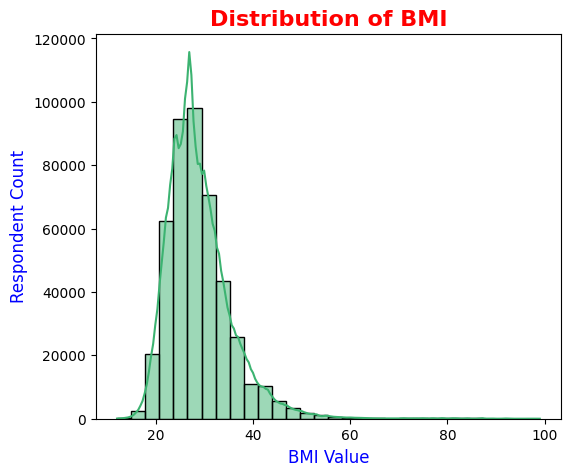

In [16]:
plt.figure(figsize=(6, 5))
sns.histplot(df.BMI, color="mediumseagreen", bins=30, kde=True)

plt.title("Distribution of BMI", fontsize=16, fontweight="bold", color="red")
plt.xlabel("BMI Value", fontsize=12, color="blue")
plt.ylabel("Respondent Count", fontsize=12, color="blue")

plt.savefig(ASSET_DIR / "BMI.png", dpi=300, bbox_inches="tight")
plt.show()

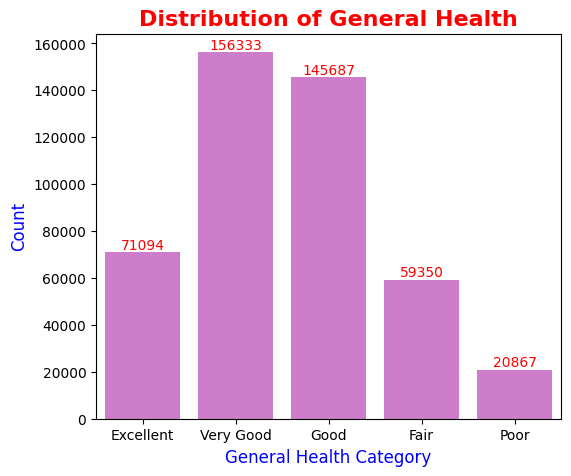

In [17]:
df["GenHlth_Label"] = df["GenHlth"].map({
    1: "Excellent",
    2: "Very Good",
    3: "Good",
    4: "Fair",
    5: "Poor",
})

plt.figure(figsize=(6, 5))
ax = sns.countplot(
    x=df.GenHlth_Label,
    order=["Excellent", "Very Good", "Good", "Fair", "Poor"],
    color="orchid",
)
for i in ax.containers:
  ax.bar_label(i, color="red")

plt.title(
    "Distribution of General Health", fontsize=16, fontweight="bold", color="red"
)
plt.xlabel("General Health Category", fontsize=12, color="blue")
plt.ylabel("Count", fontsize=12, color="blue")

plt.savefig(ASSET_DIR / "GenHlth.png", dpi=300, bbox_inches="tight")
plt.show()

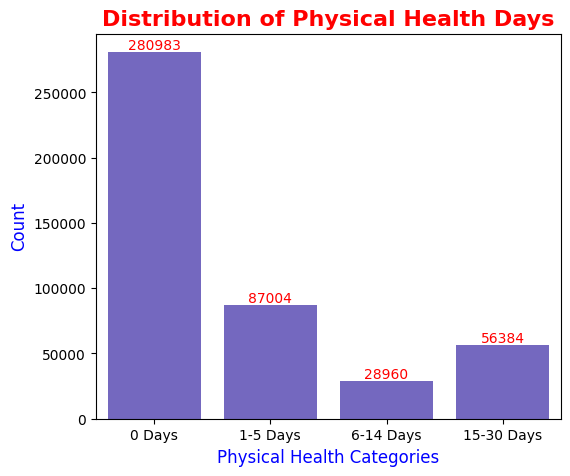

In [18]:
bins = [-1, 0.5, 5.5, 14.5, 30.5]
labels = ["0 Days", "1-5 Days", "6-14 Days", "15-30 Days"]
df["PhysHlth_Cat"] = pd.cut(df["PhysHlth"], bins=bins, labels=labels)

plt.figure(figsize=(6, 5))
ax = sns.countplot(x=df.PhysHlth_Cat, color="slateblue")
for i in ax.containers:
  ax.bar_label(i, color="red")

plt.title(
    "Distribution of Physical Health Days",
    fontsize=16,
    fontweight="bold",
    color="red",
)
plt.xlabel("Physical Health Categories", fontsize=12, color="blue")
plt.ylabel("Count", fontsize=12, color="blue")

plt.savefig(ASSET_DIR / "PhysHlth.png", dpi=300, bbox_inches="tight")
plt.show()

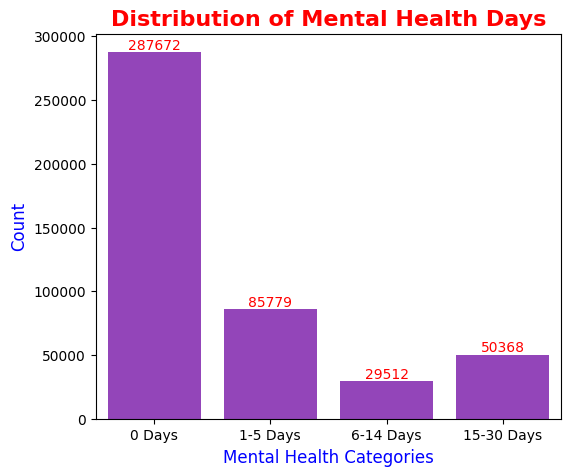

In [19]:
bins = [-1, 0.5, 5.5, 14.5, 30.5]
labels = ["0 Days", "1-5 Days", "6-14 Days", "15-30 Days"]
df["MentHlth_Cat"] = pd.cut(df["MentHlth"], bins=bins, labels=labels)

plt.figure(figsize=(6, 5))
ax = sns.countplot(x=df["MentHlth_Cat"], color="darkorchid")
for i in ax.containers:
  ax.bar_label(i, color="red")

plt.title(
    "Distribution of Mental Health Days", fontsize=16, fontweight="bold", color="red"
)
plt.xlabel("Mental Health Categories", fontsize=12, color="blue")
plt.ylabel("Count", fontsize=12, color="blue")

plt.savefig(ASSET_DIR / "MentHlth.png", dpi=300, bbox_inches="tight")
plt.show()

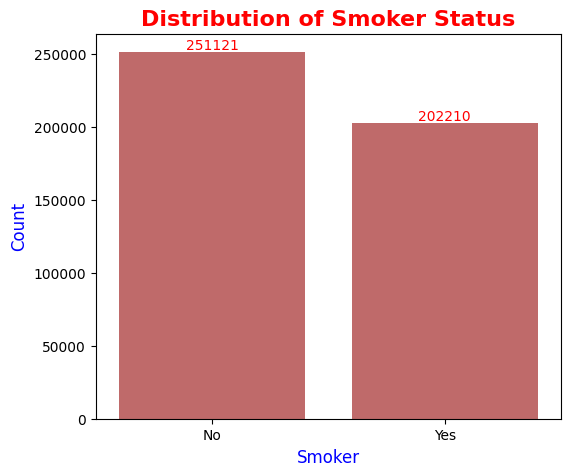

In [20]:
df["Smoker_Label"] = df["Smoker"].map({0.0: "No", 1.0: "Yes"})

plt.figure(figsize=(6, 5))
ax = sns.countplot(
    x=df.Smoker_Label, order=["No", "Yes"], color="indianred"
)
for i in ax.containers:
  ax.bar_label(i, color="red")

plt.title("Distribution of Smoker Status", fontsize=16, fontweight="bold", color="red")
plt.xlabel("Smoker", fontsize=12, color="blue")
plt.ylabel("Count", fontsize=12, color="blue")

plt.savefig(ASSET_DIR / "Smoker.png", dpi=300, bbox_inches="tight")
plt.show()

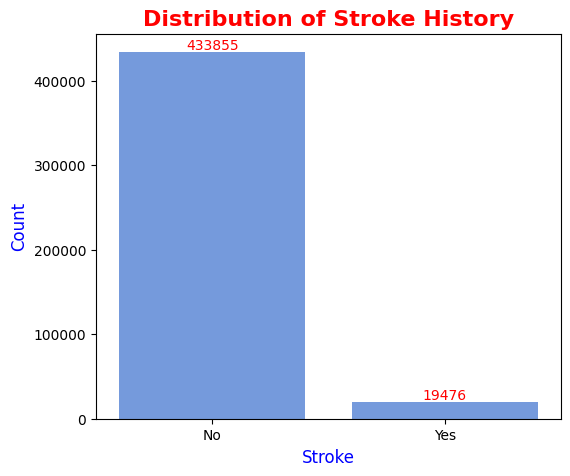

In [21]:
df["Stroke_Label"] = df["Stroke"].map({0.0: "No", 1.0: "Yes"})

plt.figure(figsize=(6, 5))
ax = sns.countplot(
    x=df.Stroke_Label, order=["No", "Yes"], color="cornflowerblue"
)
for i in ax.containers:
  ax.bar_label(i, color="red")

plt.title("Distribution of Stroke History", fontsize=16, fontweight="bold", color="red")
plt.xlabel("Stroke", fontsize=12, color="blue")
plt.ylabel("Count", fontsize=12, color="blue")

plt.savefig(ASSET_DIR / "Stroke.png", dpi=300, bbox_inches="tight")
plt.show()

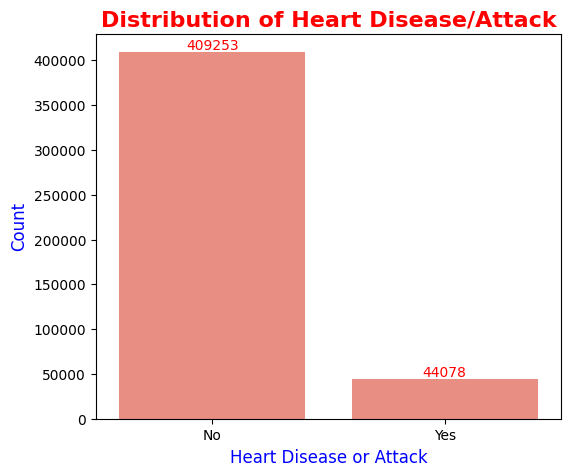

In [22]:
df["HeartDisease_Label"] = df["HeartDiseaseorAttack"].map({0.0: "No", 1.0: "Yes"})

plt.figure(figsize=(6, 5))
ax = sns.countplot(
    x=df.HeartDisease_Label, order=["No", "Yes"], color="salmon"
)
for i in ax.containers:
  ax.bar_label(i, color="red")

plt.title(
    "Distribution of Heart Disease/Attack",
    fontsize=16,
    fontweight="bold",
    color="red",
)
plt.xlabel("Heart Disease or Attack", fontsize=12, color="blue")
plt.ylabel("Count", fontsize=12, color="blue")

plt.savefig(ASSET_DIR / "HeartDiseaseorAttack.png", dpi=300, bbox_inches="tight")
plt.show()

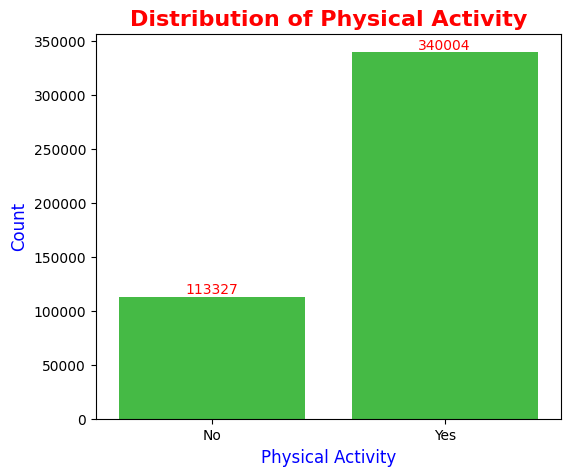

In [23]:
df["PhysActivity_Label"] = df["PhysActivity"].map({0.0: "No", 1.0: "Yes"})

plt.figure(figsize=(6, 5))
ax = sns.countplot(
    x=df.PhysActivity_Label, order=["No", "Yes"], color="limegreen"
)
for i in ax.containers:
  ax.bar_label(i, color="red")

plt.title(
    "Distribution of Physical Activity", fontsize=16, fontweight="bold", color="red"
)
plt.xlabel("Physical Activity", fontsize=12, color="blue")
plt.ylabel("Count", fontsize=12, color="blue")

plt.savefig(ASSET_DIR / "PhysActivity.png", dpi=300, bbox_inches="tight")
plt.show()

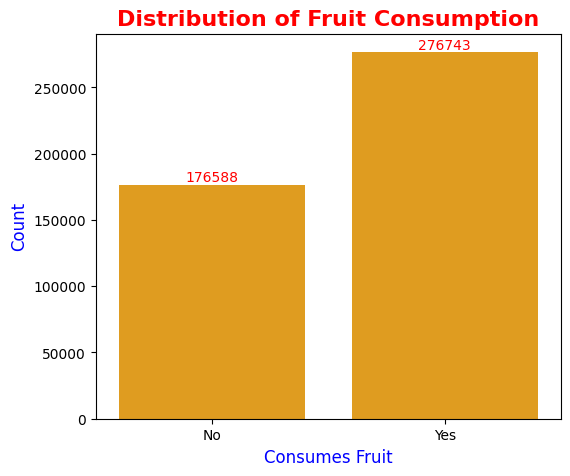

In [24]:
df["Fruits_Label"] = df["Fruits"].map({0.0: "No", 1.0: "Yes"})

plt.figure(figsize=(6, 5))
ax = sns.countplot(x=df.Fruits_Label, order=["No", "Yes"], color="orange")
for i in ax.containers:
  ax.bar_label(i, color="red")

plt.title(
    "Distribution of Fruit Consumption", fontsize=16, fontweight="bold", color="red"
)
plt.xlabel("Consumes Fruit", fontsize=12, color="blue")
plt.ylabel("Count", fontsize=12, color="blue")

plt.savefig(ASSET_DIR / "Fruits.png", dpi=300, bbox_inches="tight")
plt.show()

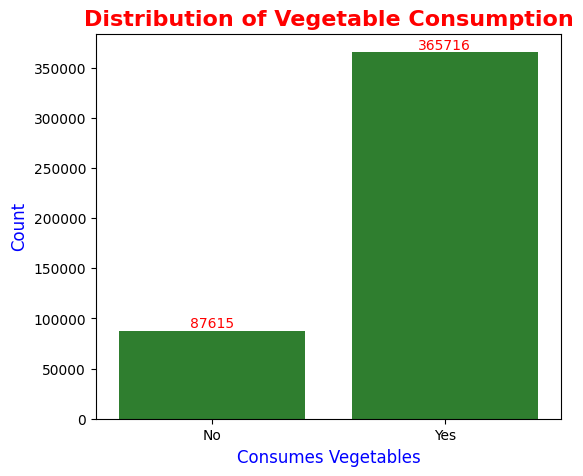

In [25]:
df["Veggies_Label"] = df["Veggies"].map({0.0: "No", 1.0: "Yes"})

plt.figure(figsize=(6, 5))
ax = sns.countplot(
    x=df.Veggies_Label, order=["No", "Yes"], color="forestgreen"
)
for i in ax.containers:
  ax.bar_label(i, color="red")

plt.title(
    "Distribution of Vegetable Consumption",
    fontsize=16,
    fontweight="bold",
    color="red",
)
plt.xlabel("Consumes Vegetables", fontsize=12, color="blue")
plt.ylabel("Count", fontsize=12, color="blue")

plt.savefig(ASSET_DIR / "Veggies.png", dpi=300, bbox_inches="tight")
plt.show()

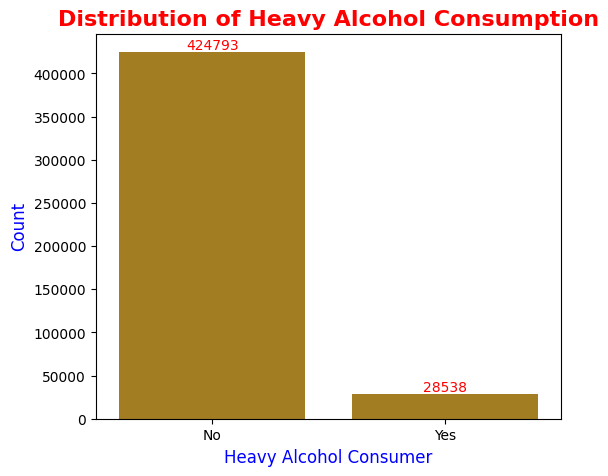

In [26]:
df["HvyAlcohol_Label"] = df["HvyAlcoholConsump"].map({0.0: "No", 1.0: "Yes"})

plt.figure(figsize=(6, 5))
ax = sns.countplot(
    x=df.HvyAlcohol_Label, order=["No", "Yes"], color="darkgoldenrod"
)
for i in ax.containers:
  ax.bar_label(i, color="red")

plt.title(
    "Distribution of Heavy Alcohol Consumption",
    fontsize=16,
    fontweight="bold",
    color="red",
)
plt.xlabel("Heavy Alcohol Consumer", fontsize=12, color="blue")
plt.ylabel("Count", fontsize=12, color="blue")

plt.savefig(ASSET_DIR / "HvyAlcoholConsump.png", dpi=300, bbox_inches="tight")
plt.show()

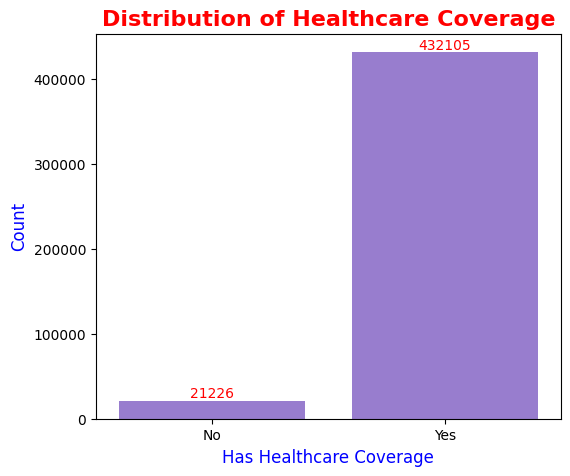

In [27]:
df["Healthcare_Label"] = df["AnyHealthcare"].map({0.0: "No", 1.0: "Yes"})

plt.figure(figsize=(6, 5))
ax = sns.countplot(
    x=df.Healthcare_Label, order=["No", "Yes"], color="mediumpurple"
)
for i in ax.containers:
  ax.bar_label(i, color="red")

plt.title(
    "Distribution of Healthcare Coverage",
    fontsize=16,
    fontweight="bold",
    color="red",
)
plt.xlabel("Has Healthcare Coverage", fontsize=12, color="blue")
plt.ylabel("Count", fontsize=12, color="blue")

plt.savefig(ASSET_DIR / "AnyHealthcare.png", dpi=300, bbox_inches="tight")
plt.show()

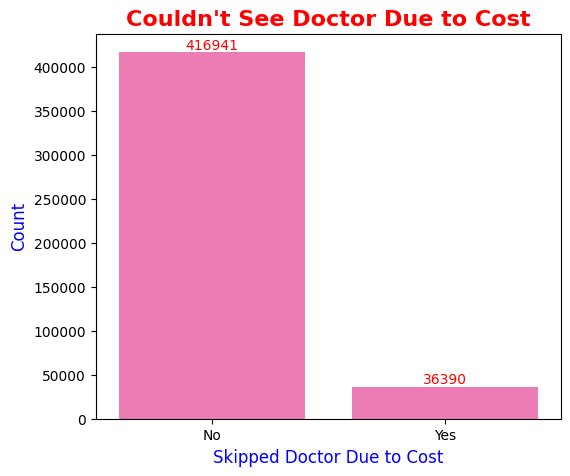

In [28]:
df["NoDocCost_Label"] = df["NoDocbcCost"].map({0.0: "No", 1.0: "Yes"})

plt.figure(figsize=(6, 5))
ax = sns.countplot(
    x=df.NoDocCost_Label, order=["No", "Yes"], color="hotpink"
)
for i in ax.containers:
  ax.bar_label(i, color="red")

plt.title(
    "Couldn't See Doctor Due to Cost", fontsize=16, fontweight="bold", color="red"
)
plt.xlabel("Skipped Doctor Due to Cost", fontsize=12, color="blue")
plt.ylabel("Count", fontsize=12, color="blue")

plt.savefig(ASSET_DIR / "NoDocbcCost.png", dpi=300, bbox_inches="tight")
plt.show()

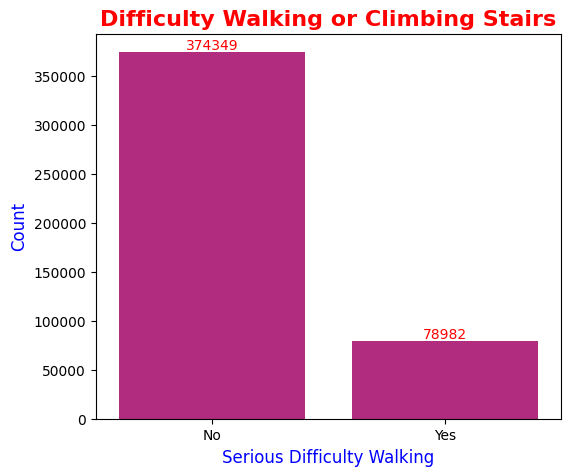

In [29]:
df["DiffWalk_Label"] = df["DiffWalk"].map({0.0: "No", 1.0: "Yes"})

plt.figure(figsize=(6, 5))
ax = sns.countplot(
    x=df.DiffWalk_Label, order=["No", "Yes"], color="mediumvioletred"
)
for i in ax.containers:
  ax.bar_label(i, color="red")

plt.title(
    "Difficulty Walking or Climbing Stairs",
    fontsize=16,
    fontweight="bold",
    color="red",
)
plt.xlabel("Serious Difficulty Walking", fontsize=12, color="blue")
plt.ylabel("Count", fontsize=12, color="blue")

plt.savefig(ASSET_DIR / "DiffWalk.png", dpi=300, bbox_inches="tight")
plt.show()

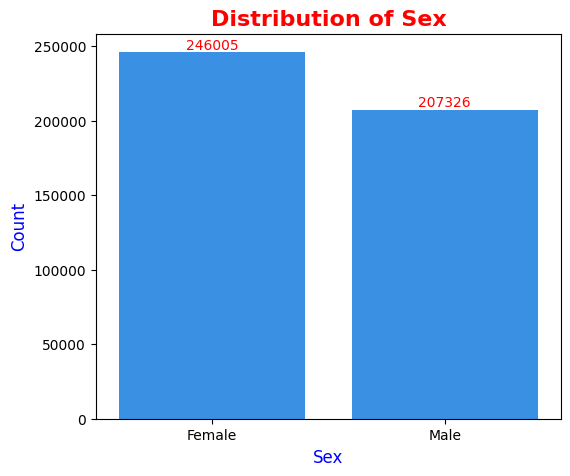

In [30]:
df["Sex_Label"] = df["Sex"].map({0.0: "Female", 1.0: "Male"})

plt.figure(figsize=(6, 5))
ax = sns.countplot(
    x=df.Sex_Label, order=["Female", "Male"], color="dodgerblue"
)
for i in ax.containers:
  ax.bar_label(i, color="red")

plt.title("Distribution of Sex", fontsize=16, fontweight="bold", color="red")
plt.xlabel("Sex", fontsize=12, color="blue")
plt.ylabel("Count", fontsize=12, color="blue")

plt.savefig(ASSET_DIR / "Sex.png", dpi=300, bbox_inches="tight")
plt.show()

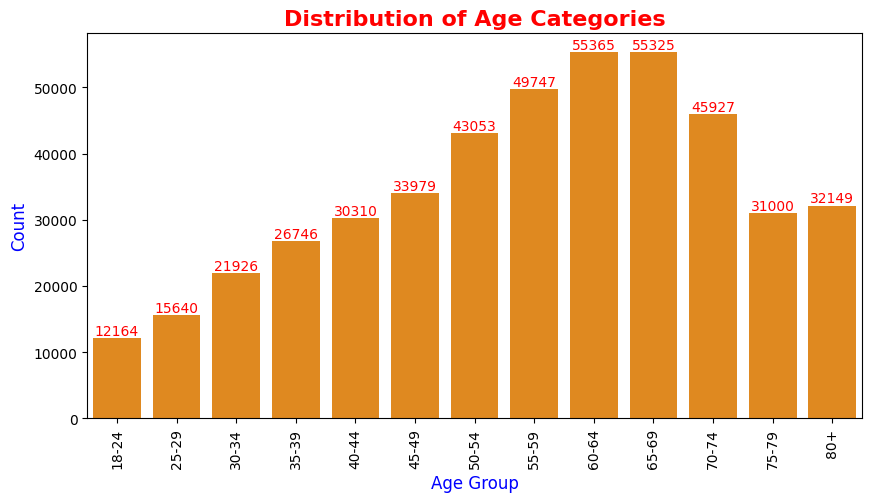

In [31]:
age_mapping = {
    1: "18-24",
    2: "25-29",
    3: "30-34",
    4: "35-39",
    5: "40-44",
    6: "45-49",
    7: "50-54",
    8: "55-59",
    9: "60-64",
    10: "65-69",
    11: "70-74",
    12: "75-79",
    13: "80+",
}
df["Age_Label"] = df["Age"].map(age_mapping)

plt.figure(figsize=(10, 5))  # Slightly wider to fit age groups comfortably
ax = sns.countplot(
    x=df.Age_Label, order=list(age_mapping.values()), color="darkorange"
)
for i in ax.containers:
  ax.bar_label(i, color="red")

plt.title(
    "Distribution of Age Categories", fontsize=16, fontweight="bold", color="red"
)
plt.xlabel("Age Group", fontsize=12, color="blue")
plt.xticks(rotation=90)
plt.ylabel("Count", fontsize=12, color="blue")

plt.savefig(ASSET_DIR / "Age.png", dpi=300, bbox_inches="tight")
plt.show()

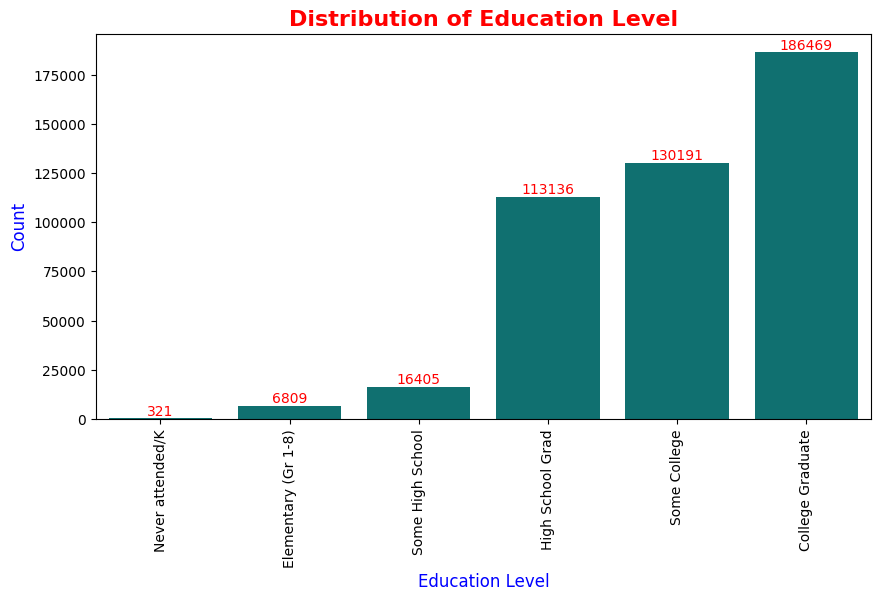

In [32]:
edu_mapping = {
    1: "Never attended/K",
    2: "Elementary (Gr 1-8)",
    3: "Some High School",
    4: "High School Grad",
    5: "Some College",
    6: "College Graduate",
}
df["Edu_Label"] = df["Education"].map(edu_mapping)

plt.figure(figsize=(10, 5))
ax = sns.countplot(
    x=df.Edu_Label, order=list(edu_mapping.values()), color="teal"
)
for i in ax.containers:
  ax.bar_label(i, color="red")

plt.title(
    "Distribution of Education Level", fontsize=16, fontweight="bold", color="red"
)
plt.xlabel("Education Level", fontsize=12, color="blue")
plt.xticks(rotation=90)
plt.ylabel("Count", fontsize=12, color="blue")

plt.savefig(ASSET_DIR / "Education.png", dpi=300, bbox_inches="tight")
plt.show()

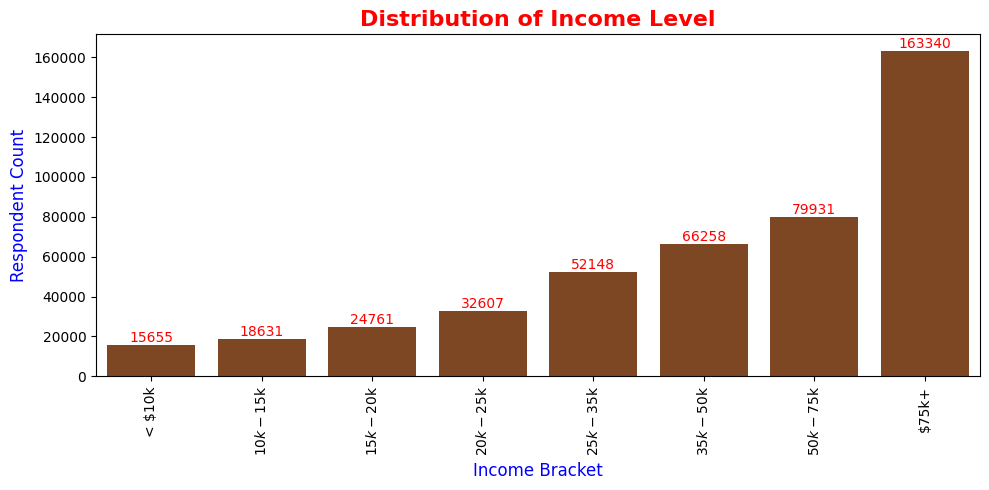

In [33]:
# Combine the upper income categories into a shared $75k+ group.
df["Income_Harmonized"] = np.where(
    df["Income"] >= 8, 8, df["Income"]
).astype(int)

income_mapping = {
    1: "< $10k",
    2: "$10k-$15k",
    3: "$15k-$20k",
    4: "$20k-$25k",
    5: "$25k-$35k",
    6: "$35k-$50k",
    7: "$50k-$75k",
    8: "$75k+",
}

df["Income_Harmonized_Label"] = (
    df["Income_Harmonized"].map(income_mapping)
)

# Keep the existing label name for any downstream cells using it.
df["Income_Label"] = df["Income_Harmonized_Label"]

plt.figure(figsize=(10, 5))
ax = sns.countplot(
    data=df,
    x="Income_Harmonized_Label",
    order=list(income_mapping.values()),
    color="saddlebrown"
)

for container in ax.containers:
    ax.bar_label(container, color="red")

plt.title(
    "Distribution of Income Level",
    fontsize=16,
    fontweight="bold",
    color="red"
)
plt.xlabel("Income Bracket", fontsize=12, color="blue")
plt.xticks(rotation=90)
plt.ylabel("Respondent Count", fontsize=12, color="blue")

plt.tight_layout()
plt.savefig(
    ASSET_DIR / "Income.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Correlation Matrix

In [34]:
df.corr(numeric_only = True)

,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Year,Health_Status,Income_Harmonized
Diabetes_012,1.000000,0.262886,0.203801,0.076312,0.208046,0.047659,0.099637,0.171691,-0.121901,-0.022710,...,0.043047,0.158063,0.209862,0.034049,0.193159,-0.101942,-0.144523,-0.001211,0.980974,-0.143771
HighBP,0.262886,1.000000,0.279769,0.108727,0.197443,0.080796,0.124506,0.200840,-0.113530,-0.019058,...,0.017295,0.139653,0.207695,0.056317,0.342933,-0.103233,-0.137927,-0.022962,0.260218,-0.133123
HighChol,0.203801,0.279769,1.000000,0.099001,0.082697,0.075015,0.087131,0.173197,-0.067352,-0.020934,...,0.029670,0.106594,0.130747,0.023645,0.274745,-0.039265,-0.063304,-0.031149,0.204644,-0.060845
CholCheck,0.076312,0.108727,0.099001,1.000000,0.042109,-0.006148,0.027659,0.048466,-0.008599,0.019342,...,-0.006041,0.038259,0.049069,-0.036666,0.100227,0.006982,0.009921,0.005051,0.076790,0.008961
BMI,0.208046,0.197443,0.082697,0.042109,1.000000,-0.005502,0.007807,0.035540,-0.138467,-0.072262,...,0.074158,0.105086,0.185501,0.018124,-0.052721,-0.075827,-0.069132,0.033222,0.208195,-0.066703
Smoker,0.047659,0.080796,0.075015,-0.006148,-0.005502,1.000000,0.053874,0.105835,-0.075389,-0.060383,...,0.073836,0.103408,0.112407,0.084673,0.115648,-0.150574,-0.119365,-0.039990,0.046779,-0.110551
Stroke,0.099637,0.124506,0.087131,0.027659,0.007807,0.053874,1.000000,0.188011,-0.066459,0.000191,...,0.050759,0.135013,0.164650,0.002530,0.129795,-0.060606,-0.112559,-0.008968,0.096586,-0.114884
HeartDiseaseorAttack,0.171691,0.200840,0.173197,0.048466,0.035540,0.105835,0.188011,1.000000,-0.082141,-0.003223,...,0.039340,0.168574,0.196970,0.088229,0.225610,-0.078709,-0.120834,-0.020478,0.166911,-0.120156
PhysActivity,-0.121901,-0.113530,-0.067352,-0.008599,-0.138467,-0.075389,-0.066459,-0.082141,1.000000,0.116047,...,-0.103120,-0.218958,-0.255435,0.047049,-0.105318,0.185860,0.200242,0.039003,-0.119717,0.193040
Fruits,-0.022710,-0.019058,-0.020934,0.019342,-0.072262,-0.060383,0.000191,-0.003223,0.116047,1.000000,...,-0.049618,-0.022621,-0.024458,-0.071583,0.073470,0.077660,0.041178,-0.005199,-0.022513,0.041834


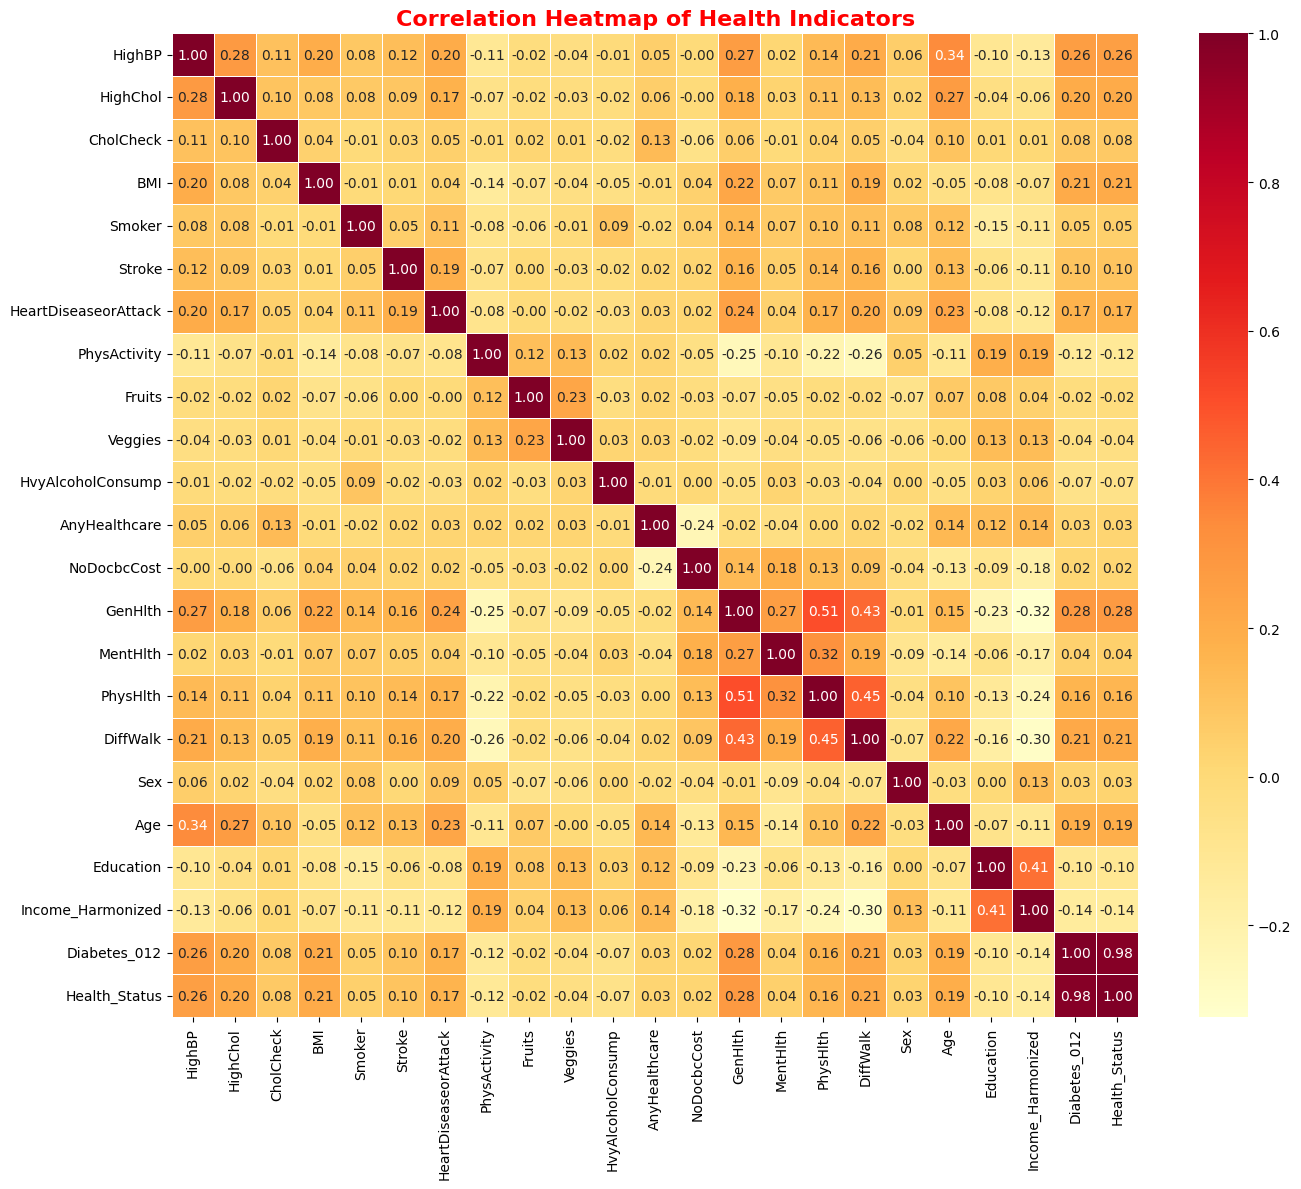

In [35]:
correlation_features = [
    "HighBP", "HighChol", "CholCheck", "BMI", "Smoker",
    "Stroke", "HeartDiseaseorAttack", "PhysActivity",
    "Fruits", "Veggies", "HvyAlcoholConsump",
    "AnyHealthcare", "NoDocbcCost", "GenHlth",
    "MentHlth", "PhysHlth", "DiffWalk", "Sex",
    "Age", "Education", "Income_Harmonized",
    "Diabetes_012", "Health_Status"
]

correlation_matrix = df[correlation_features].corr(
    numeric_only=True
)

plt.figure(figsize=(14, 12))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    linewidths=0.5
)

plt.title(
    "Correlation Heatmap of Health Indicators",
    fontsize=16,
    fontweight="bold",
    color="red"
)

plt.tight_layout()
plt.savefig(
    ASSET_DIR / "Correlation_Heatmap.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Conditional Distributions (Faceted Box / Violin Plots)

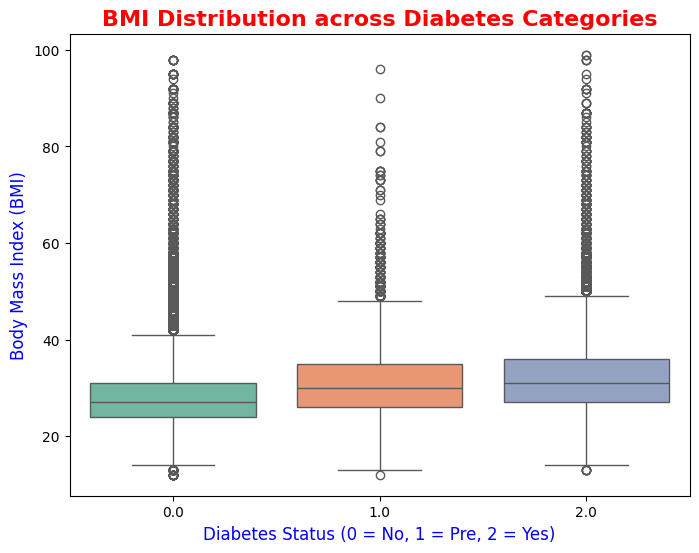

In [36]:
plt.figure(figsize=(8, 6))
sns.boxplot(data=df, x="Diabetes_012", y="BMI", palette="Set2")
plt.title(
    "BMI Distribution across Diabetes Categories",
    fontsize=16,
    fontweight="bold",
    color="red",
)
plt.xlabel("Diabetes Status (0 = No, 1 = Pre, 2 = Yes)", fontsize=12, color="blue")
plt.ylabel("Body Mass Index (BMI)", fontsize=12, color="blue")
plt.savefig(ASSET_DIR / "BMI_vs_Diabetes_Boxplot.png", dpi=300, bbox_inches="tight")
plt.show()

# Risk Factor Heatmap / Grouped Proportions (Cross-Tabulation)

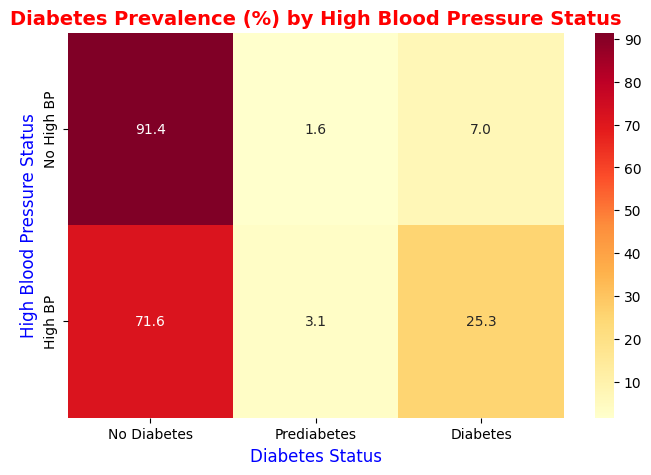

In [37]:
cross_tab = pd.crosstab(df["HighBP"], df["Diabetes_012"], normalize="index") * 100

cross_tab.index = ["No High BP", "High BP"]
cross_tab.columns = ["No Diabetes", "Prediabetes", "Diabetes"]

plt.figure(figsize=(8, 5))
sns.heatmap(cross_tab, annot=True, fmt=".1f", cmap="YlOrRd", cbar=True)
plt.title(
    "Diabetes Prevalence (%) by High Blood Pressure Status",
    fontsize=14,
    fontweight="bold",
    color="red",
)
plt.xlabel("Diabetes Status", fontsize=12, color="blue")
plt.ylabel("High Blood Pressure Status", fontsize=12, color="blue")
plt.savefig(ASSET_DIR / "HighBP_vs_Diabetes_Heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

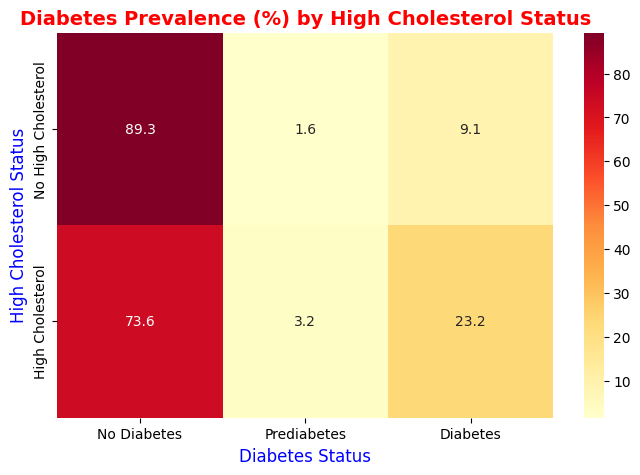

In [38]:
cross_tab_chol = pd.crosstab(df["HighChol"], df["Diabetes_012"], normalize="index") * 100

cross_tab_chol.index = ["No High Cholesterol", "High Cholesterol"]
cross_tab_chol.columns = ["No Diabetes", "Prediabetes", "Diabetes"]  

plt.figure(figsize=(8, 5))
sns.heatmap(cross_tab_chol, annot=True, fmt=".1f", cmap="YlOrRd", cbar=True)

plt.title(
    "Diabetes Prevalence (%) by High Cholesterol Status",
    fontsize=14,
    fontweight="bold",
    color="red",
)
plt.xlabel("Diabetes Status", fontsize=12, color="blue")
plt.ylabel("High Cholesterol Status", fontsize=12, color="blue")

plt.savefig(ASSET_DIR / "HighChol_vs_Diabetes_Heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

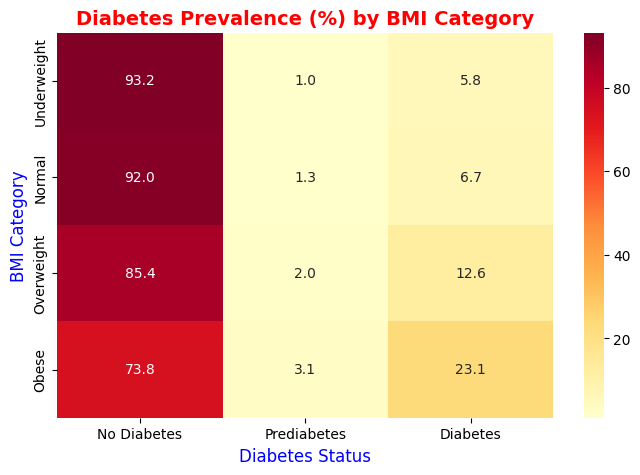

In [39]:
cross_tab_bmi = pd.crosstab(df["BMICat"], df["Diabetes_012"], normalize="index") * 100
cross_tab_bmi.columns = ["No Diabetes", "Prediabetes", "Diabetes"]  

plt.figure(figsize=(8, 5))
sns.heatmap(cross_tab_bmi, annot=True, fmt=".1f", cmap="YlOrRd", cbar=True)

plt.title(
    "Diabetes Prevalence (%) by BMI Category",
    fontsize=14,
    fontweight="bold",
    color="red",
)
plt.xlabel("Diabetes Status", fontsize=12, color="blue")
plt.ylabel("BMI Category", fontsize=12, color="blue")

plt.savefig(ASSET_DIR / "BMI_vs_Diabetes_Heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

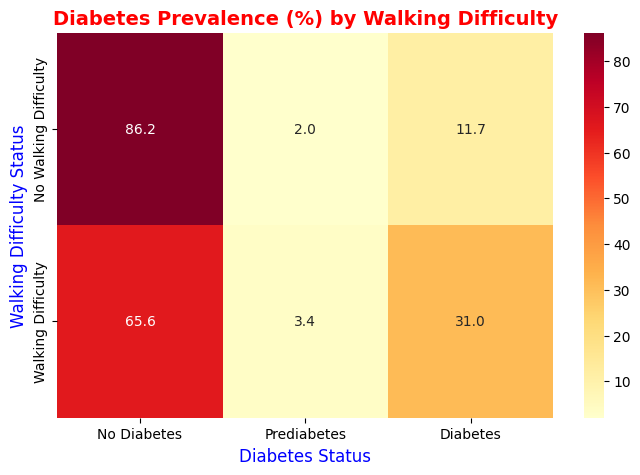

In [40]:
cross_tab_walk = pd.crosstab(df["DiffWalk"], df["Diabetes_012"], normalize="index") * 100
cross_tab_walk.index = ["No Walking Difficulty", "Walking Difficulty"]
cross_tab_walk.columns = ["No Diabetes", "Prediabetes", "Diabetes"] 

plt.figure(figsize=(8, 5))
sns.heatmap(cross_tab_walk, annot=True, fmt=".1f", cmap="YlOrRd", cbar=True)

plt.title(
    "Diabetes Prevalence (%) by Walking Difficulty",
    fontsize=14,
    fontweight="bold",
    color="red",
)
plt.xlabel("Diabetes Status", fontsize=12, color="blue")
plt.ylabel("Walking Difficulty Status", fontsize=12, color="blue")

plt.savefig(ASSET_DIR / "DiffWalk_vs_Diabetes_Heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

# Socioeconomic Disparities Plot

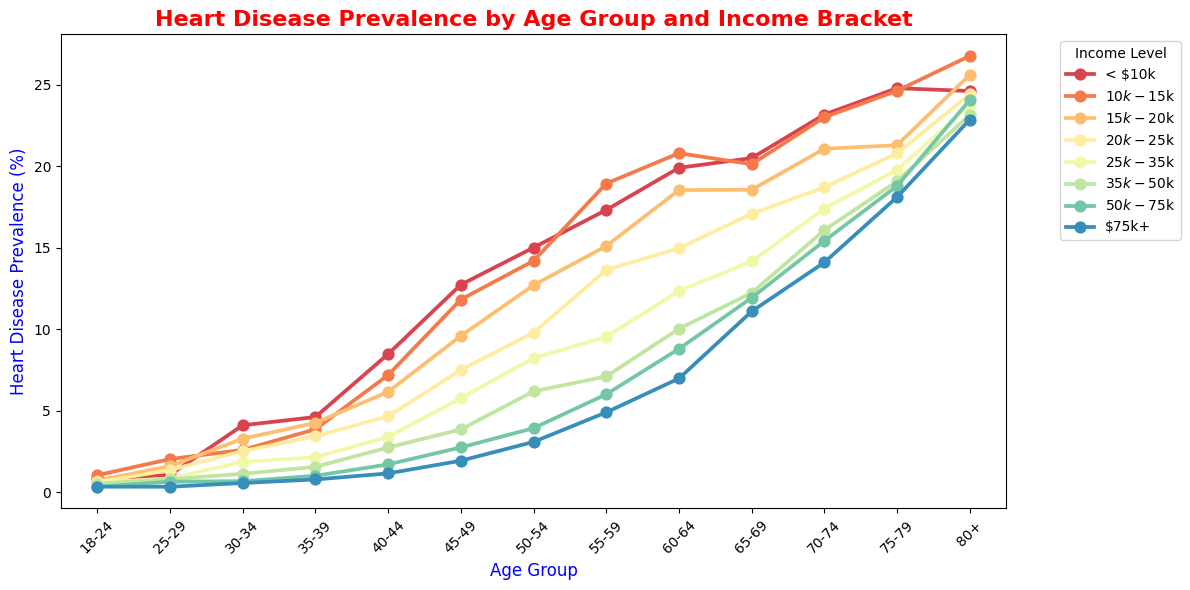

In [41]:
age_mapping = {
    1: "18-24", 2: "25-29", 3: "30-34",
    4: "35-39", 5: "40-44", 6: "45-49",
    7: "50-54", 8: "55-59", 9: "60-64",
    10: "65-69", 11: "70-74",
    12: "75-79", 13: "80+"
}

income_mapping = {
    1: "< $10k",
    2: "$10k-$15k",
    3: "$15k-$20k",
    4: "$20k-$25k",
    5: "$25k-$35k",
    6: "$35k-$50k",
    7: "$50k-$75k",
    8: "$75k+"
}

df["Age_Label"] = df["Age"].map(age_mapping)
df["Income_Harmonized_Label"] = (
    df["Income_Harmonized"].map(income_mapping)
)

# Convert the binary indicator into a percentage scale.
df["HeartDisease_Percent"] = (
    df["HeartDiseaseorAttack"] * 100
)

plt.figure(figsize=(12, 6))

sns.pointplot(
    data=df,
    x="Age_Label",
    y="HeartDisease_Percent",
    hue="Income_Harmonized_Label",
    order=list(age_mapping.values()),
    hue_order=list(income_mapping.values()),
    palette="Spectral",
    errorbar=None,
    markers="o",
    linestyles="-"
)

plt.title(
    "Heart Disease Prevalence by Age Group and Income Bracket",
    fontsize=16,
    fontweight="bold",
    color="red"
)
plt.xlabel("Age Group", fontsize=12, color="blue")
plt.ylabel("Heart Disease Prevalence (%)", fontsize=12, color="blue")
plt.xticks(rotation=45)

plt.legend(
    title="Income Level",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.savefig(
    ASSET_DIR / "Socioeconomic_HeartDisease_Trend.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

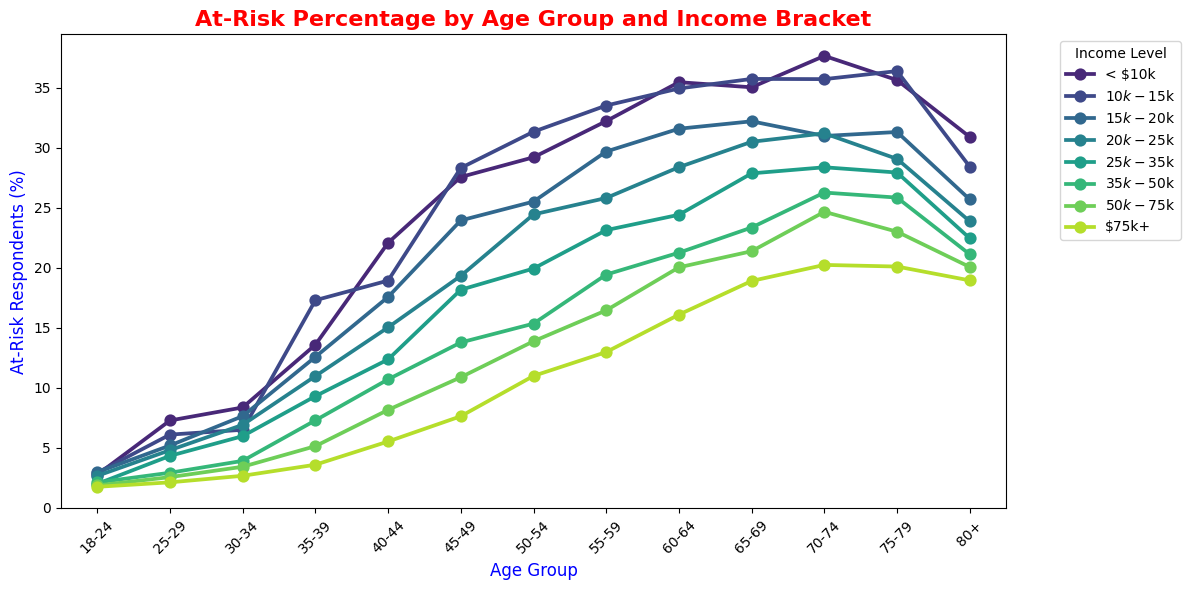

In [42]:
age_mapping = {
    1: "18-24", 2: "25-29", 3: "30-34",
    4: "35-39", 5: "40-44", 6: "45-49",
    7: "50-54", 8: "55-59", 9: "60-64",
    10: "65-69", 11: "70-74",
    12: "75-79", 13: "80+"
}

income_mapping = {
    1: "< $10k",
    2: "$10k-$15k",
    3: "$15k-$20k",
    4: "$20k-$25k",
    5: "$25k-$35k",
    6: "$35k-$50k",
    7: "$50k-$75k",
    8: "$75k+"
}

df["Age_Label"] = df["Age"].map(age_mapping)
df["Income_Harmonized_Label"] = (
    df["Income_Harmonized"].map(income_mapping)
)

# Health_Status is 1 for the combined prediabetes/diabetes class.
df["AtRisk_Percent"] = df["Health_Status"] * 100

plt.figure(figsize=(12, 6))

sns.pointplot(
    data=df,
    x="Age_Label",
    y="AtRisk_Percent",
    hue="Income_Harmonized_Label",
    order=list(age_mapping.values()),
    hue_order=list(income_mapping.values()),
    palette="viridis",
    errorbar=None,
    markers="o",
    linestyles="-"
)

plt.title(
    "At-Risk Percentage by Age Group and Income Bracket",
    fontsize=16,
    fontweight="bold",
    color="red"
)
plt.xlabel("Age Group", fontsize=12, color="blue")
plt.ylabel("At-Risk Respondents (%)", fontsize=12, color="blue")
plt.xticks(rotation=45)

plt.legend(
    title="Income Level",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.savefig(
    ASSET_DIR / "Socioeconomic_Diabetes_Trend.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Mutual Information Feature Importance

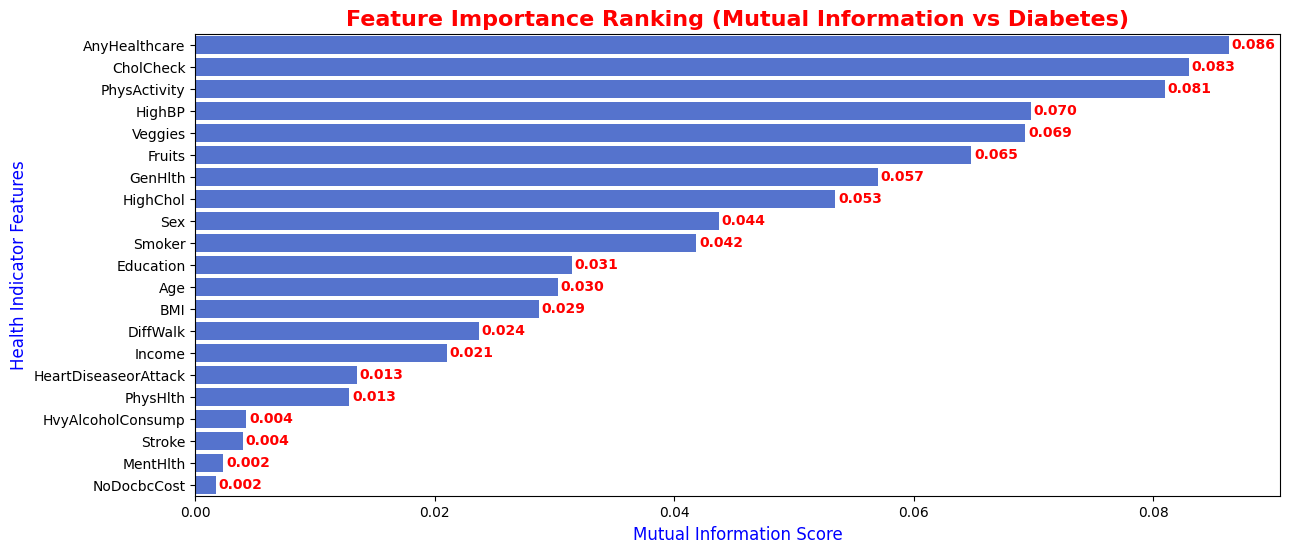

In [43]:
target_col = 'Diabetes_012'
features = [
    'HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke',
    'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies',
    'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth',
    'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income'
]

X = df[features]
y = df[target_col]

mi_scores = mutual_info_classif(X, y, random_state=42)

mi_df = pd.DataFrame({'Feature': features, 'MI_Score': mi_scores})
mi_df = mi_df.sort_values(by='MI_Score', ascending=False) 

plt.figure(figsize=(14, 6))
ax = sns.barplot(
    data=mi_df,
    x='MI_Score',
    y='Feature',
    color='royalblue'
)

for i in ax.containers:
    ax.bar_label(i, fmt='%.3f', padding=2, color='red', fontweight='bold')

plt.title(
    'Feature Importance Ranking (Mutual Information vs Diabetes)',
    fontsize=16,
    fontweight='bold',
    color='red'
)
plt.xlabel('Mutual Information Score', fontsize=12, color='blue')
plt.ylabel('Health Indicator Features', fontsize=12, color='blue')



plt.savefig(ASSET_DIR / 'Mutual_Information_Ranking.png', dpi=300, bbox_inches='tight')
plt.show()

# 3-Class Exploratory Data Analysis (EDA): Diabetes Progression (Diabetes_012)
Exploring the distribution, risk gradients, comorbidity progression, and demographic shifts across **No Diabetes (0)**, **Prediabetes (1)**, and **Diabetes (2)**.

In [44]:
df["Diabetes_012_Label"] = df["Diabetes_012"].map({
    0.0: "No Diabetes", 
    1.0: "Prediabetes", 
    2.0: "Diabetes"
})

print("Class Counts:")
print(df["Diabetes_012"].value_counts())
print("\nClass Proportions (%):")
print(df["Diabetes_012"].value_counts(normalize=True) * 100)

Class Counts:
Diabetes_012
0.0    374597
2.0     68492
1.0     10242
Name: count, dtype: int64

Class Proportions (%):
Diabetes_012
0.0    82.632116
2.0    15.108607
1.0     2.259276
Name: proportion, dtype: float64


## Multi-class Target Distribution Visualization
Visualizing the class imbalance across the three health categories.

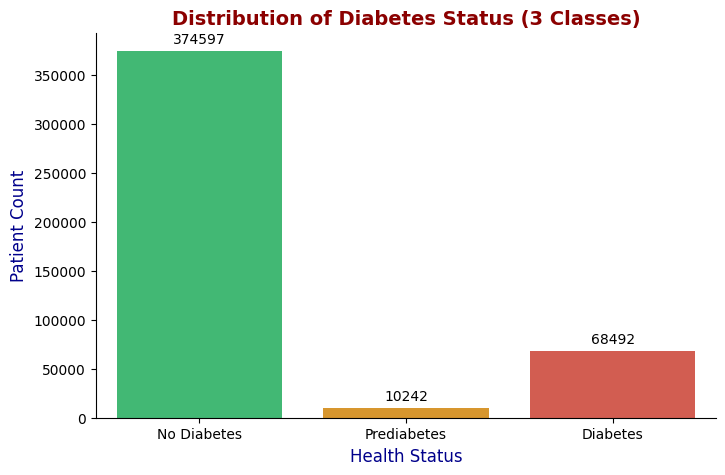

In [45]:
plt.figure(figsize=(8, 5))
ax = sns.countplot(
    data=df, 
    x="Diabetes_012_Label", 
    order=["No Diabetes", "Prediabetes", "Diabetes"],
    palette=["#2ecc71", "#f39c12", "#e74c3c"]
)

for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3)

plt.title("Distribution of Diabetes Status (3 Classes)", fontsize=14, fontweight="bold", color="darkred")
plt.xlabel("Health Status", fontsize=12, color="darkblue")
plt.ylabel("Patient Count", fontsize=12, color="darkblue")
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
sns.despine()
plt.savefig(ASSET_DIR / 'Diabetes_012_Label.png', dpi=300, bbox_inches='tight')
plt.show()

# Pie Chart for original 3-class distribution (No Diabetes, Prediabetes, and Diabetes)

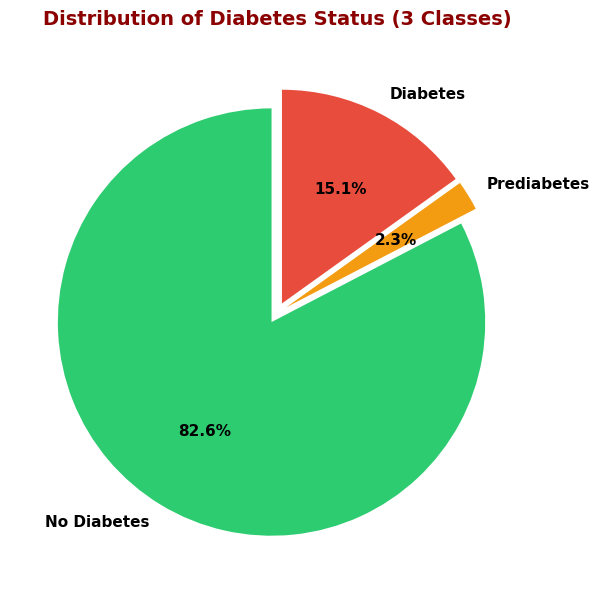

In [46]:
class_counts = df["Diabetes_012_Label"].value_counts()[
    ["No Diabetes", "Prediabetes", "Diabetes"]
]

plt.figure(figsize=(9, 6))

colors = ["#2ecc71", "#f39c12", "#e74c3c"]

plt.pie(
    class_counts,
    labels=class_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=colors,
    explode=(0.05, 0.05, 0.05),  
    shadow=False,
    textprops={"fontsize": 11, "fontweight": "bold"},
)

plt.title(
    "Distribution of Diabetes Status (3 Classes)",
    fontsize=14,
    fontweight="bold",
    color="darkred",
    pad=15,
)

plt.tight_layout()
plt.savefig(ASSET_DIR / "Diabetes_012_Label_Pie.png", dpi=300, bbox_inches="tight")
plt.show()

# Binary target distribution
## Distribution of Health_Status

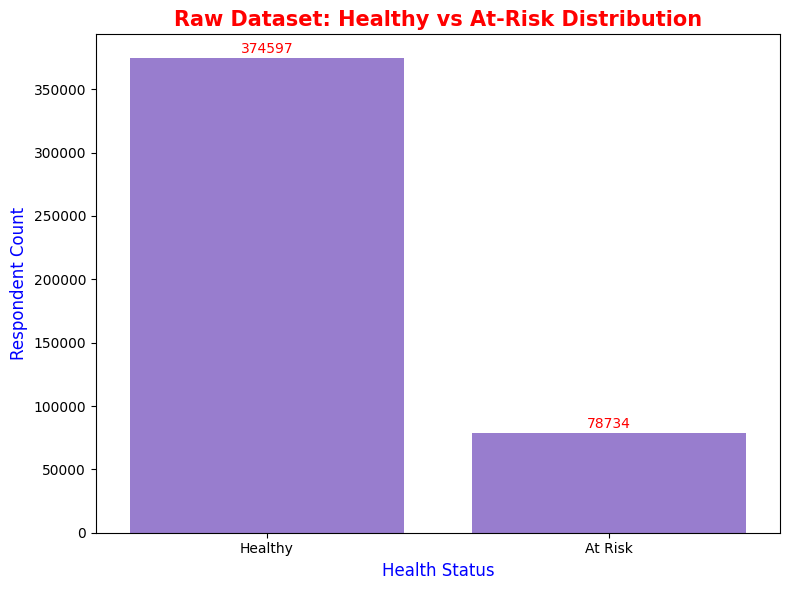

In [47]:
df["Health_Status_Label_EDA"] = df["Health_Status"].map({
    0: "Healthy",
    1: "At Risk"
})

plt.figure(figsize=(8, 6))

ax = sns.countplot(
    data=df,
    x="Health_Status_Label_EDA",
    order=["Healthy", "At Risk"],
    color="mediumpurple"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=1.5, color="red")

plt.title(
    "Raw Dataset: Healthy vs At-Risk Distribution",
    fontsize=15, fontweight="bold", color="red"
)
plt.xlabel("Health Status", fontsize=12, color="blue")
plt.ylabel("Respondent Count", fontsize=12, color="blue")

plt.tight_layout()
plt.savefig(
    ASSET_DIR / "Health_Status_Raw_Distribution.png",
    dpi=300, bbox_inches="tight"
)
plt.show()

# Pie Chart for binary Health_Status

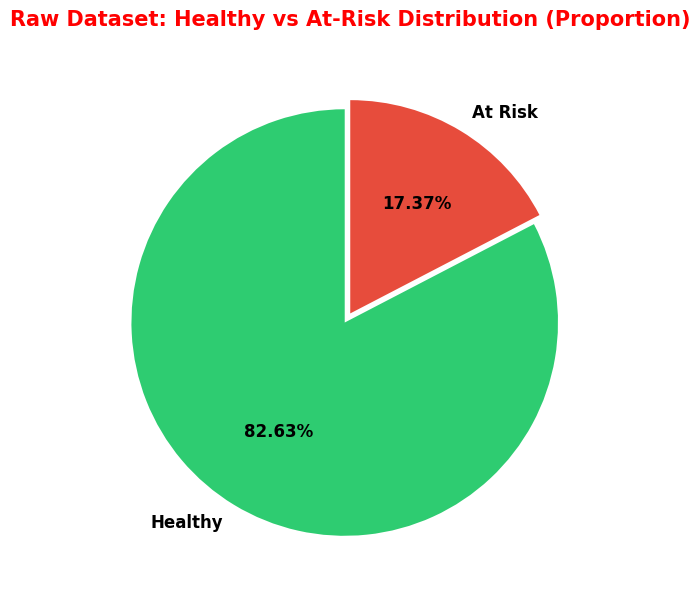

In [48]:
health_counts = df["Health_Status"].map({0: "Healthy", 1: "At Risk"}).value_counts()

plt.figure(figsize=(9, 6))

colors = ["#2ecc71", "#e74c3c"]

plt.pie(
    health_counts,
    labels=health_counts.index,
    autopct="%1.2f%%",
    startangle=90,
    colors=colors,
    explode=(0.05, 0),  
    shadow=False,
    textprops={"fontsize": 12, "fontweight": "bold"},
)

plt.title(
    "Raw Dataset: Healthy vs At-Risk Distribution (Proportion)",
    fontsize=15,
    fontweight="bold",
    color="red",
    pad=15,
)

plt.tight_layout()
plt.savefig(
    ASSET_DIR / "Health_Status_Raw_Distribution_Pie.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

# BMI vs Health Status — straight-line XY plot

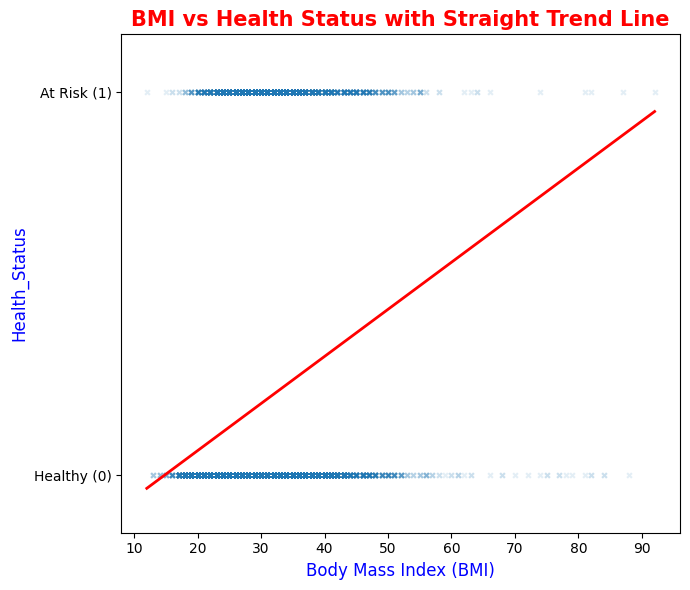

In [49]:
scatter_sample = df[["BMI", "Health_Status"]].sample(
    n=min(15000, len(df)),
    random_state=42
)

plt.figure(figsize=(7, 6))

sns.regplot(
    data=scatter_sample,
    x="BMI",
    y="Health_Status",
    ci=None,
    scatter_kws={"alpha": 0.12, "s": 12},
    line_kws={"color": "red", "linewidth": 2},
    marker='x'
)

plt.yticks([0, 1], ["Healthy (0)", "At Risk (1)"])
plt.ylim(-0.15, 1.15)

plt.title(
    "BMI vs Health Status with Straight Trend Line",
    fontsize=15, fontweight="bold", color="red"
)
plt.xlabel("Body Mass Index (BMI)", fontsize=12, color="blue")
plt.ylabel("Health_Status", fontsize=12, color="blue")

plt.tight_layout()
plt.savefig(
    ASSET_DIR / "BMI_vs_Health_Status_Scatter_Trend.png",
    dpi=300, bbox_inches="tight"
)
plt.show()

# At-Risk percentage by BMI

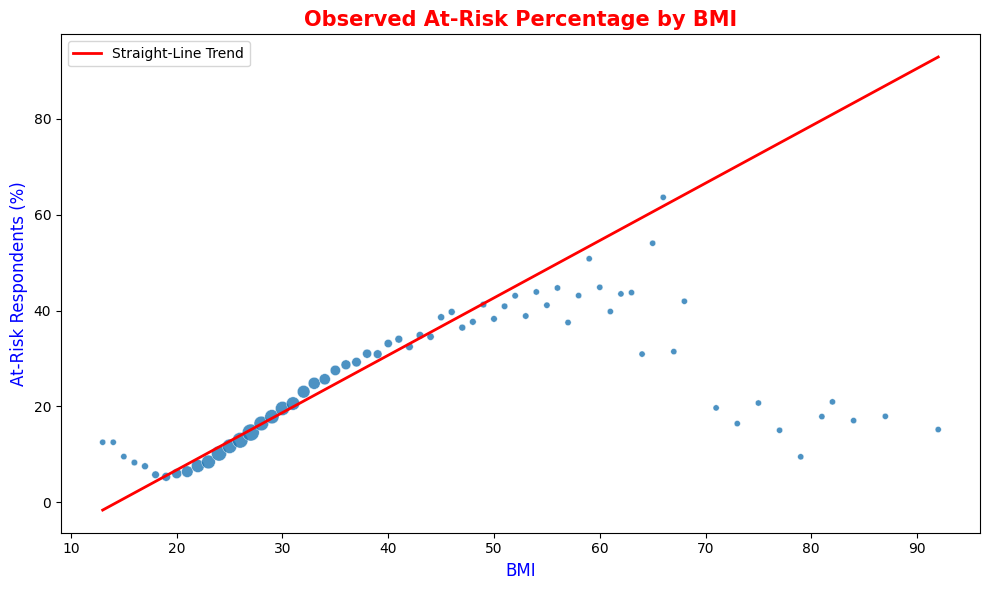

In [50]:
bmi_risk = (
    df.groupby("BMI")["Health_Status"]
    .agg(AtRisk_Rate="mean", Count="size")
    .reset_index()
)

bmi_risk["AtRisk_Percent"] = bmi_risk["AtRisk_Rate"] * 100

bmi_risk = bmi_risk[bmi_risk["Count"] >= 30].copy()

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=bmi_risk,
    x="BMI",
    y="AtRisk_Percent",
    size="Count",
    sizes=(20, 150),
    legend=False,
    alpha=0.8
)

if len(bmi_risk) >= 2:
    slope, intercept = np.polyfit(
        bmi_risk["BMI"],
        bmi_risk["AtRisk_Percent"],
        1,
        w=np.sqrt(bmi_risk["Count"])
    )

    x_line = np.linspace(
        bmi_risk["BMI"].min(),
        bmi_risk["BMI"].max(),
        100
    )

    plt.plot(
        x_line,
        slope * x_line + intercept,
        color="red",
        linewidth=2,
        label="Straight-Line Trend"
    )

    plt.legend()

plt.title(
    "Observed At-Risk Percentage by BMI",
    fontsize=15, fontweight="bold", color="red"
)
plt.xlabel("BMI", fontsize=12, color="blue")
plt.ylabel("At-Risk Respondents (%)", fontsize=12, color="blue")

plt.tight_layout()
plt.savefig(
    ASSET_DIR / "AtRisk_Percent_by_BMI.png",
    dpi=300, bbox_inches="tight"
)
plt.show()

# At-Risk percentage by binary health indicators

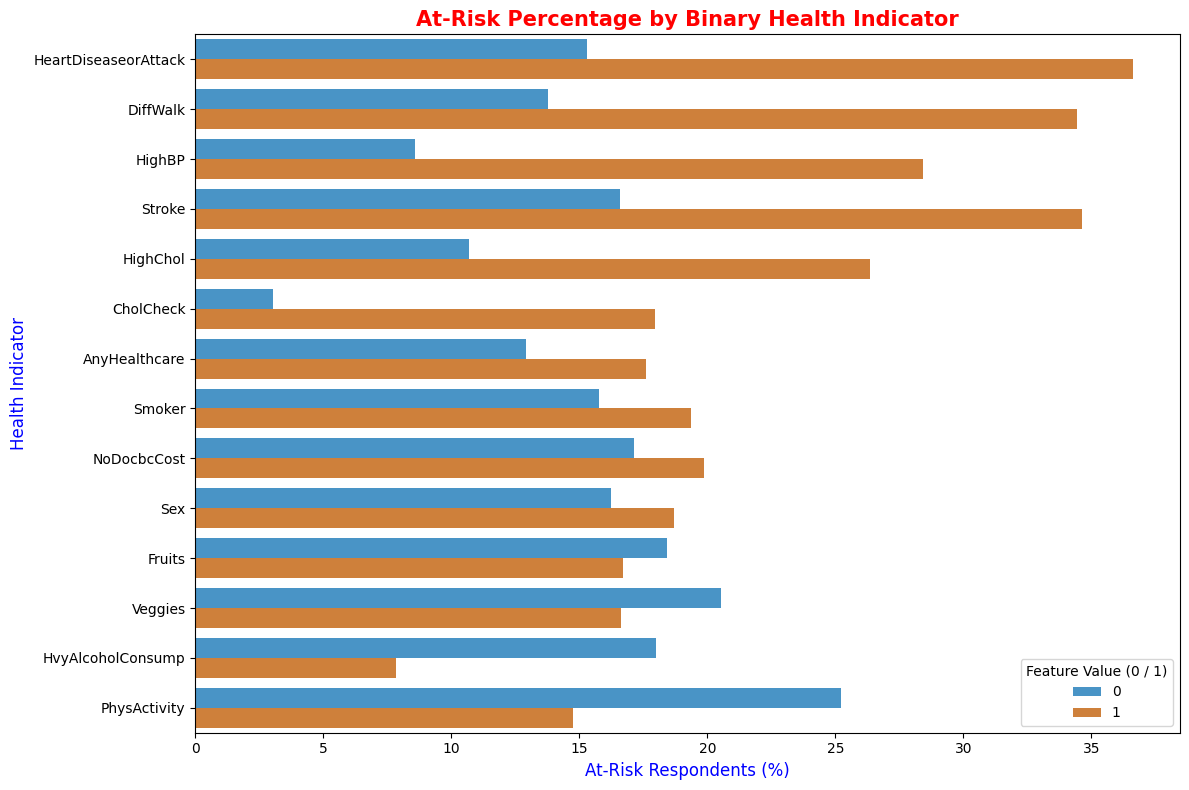

In [51]:
binary_features = [
    "HighBP", "HighChol", "CholCheck", "Smoker",
    "Stroke", "HeartDiseaseorAttack", "PhysActivity",
    "Fruits", "Veggies", "HvyAlcoholConsump",
    "AnyHealthcare", "NoDocbcCost", "DiffWalk", "Sex"
]

risk_rows = []

for feature in binary_features:
    grouped = df.groupby(feature)["Health_Status"].agg(["mean", "size"])

    for value in [0, 1]:
        if value in grouped.index:
            risk_rows.append({
                "Feature": feature,
                "Value": str(value),
                "AtRisk_Percent": grouped.loc[value, "mean"] * 100,
                "Count": grouped.loc[value, "size"]
            })

risk_by_binary = pd.DataFrame(risk_rows)

risk_pivot = risk_by_binary.pivot(
    index="Feature",
    columns="Value",
    values="AtRisk_Percent"
)

risk_pivot["Difference"] = risk_pivot["1"] - risk_pivot["0"]
feature_order = risk_pivot.sort_values(
    "Difference", ascending=False
).index.tolist()

plt.figure(figsize=(12, 8))

sns.barplot(
    data=risk_by_binary,
    x="AtRisk_Percent",
    y="Feature",
    hue="Value",
    order=feature_order,
    palette={"0": "#3498db", "1": "#e67e22"}
)

plt.title(
    "At-Risk Percentage by Binary Health Indicator",
    fontsize=15, fontweight="bold", color="red"
)
plt.xlabel("At-Risk Respondents (%)", fontsize=12, color="blue")
plt.ylabel("Health Indicator", fontsize=12, color="blue")
plt.legend(title="Feature Value (0 / 1)")

plt.tight_layout()
plt.savefig(
    ASSET_DIR / "AtRisk_by_Binary_Features.png",
    dpi=300, bbox_inches="tight"
)
plt.show()

# At-Risk percentage across age groups

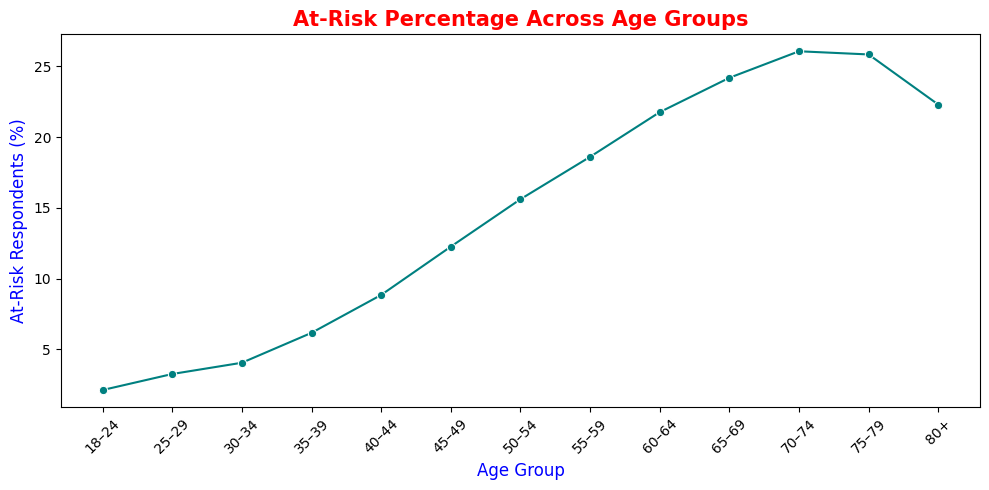

In [52]:
age_mapping = {
    1: "18–24", 2: "25–29", 3: "30–34",
    4: "35–39", 5: "40–44", 6: "45–49",
    7: "50–54", 8: "55–59", 9: "60–64",
    10: "65–69", 11: "70–74",
    12: "75–79", 13: "80+"
}

age_risk = (
    df.groupby("Age")["Health_Status"]
    .agg(AtRisk_Rate="mean", Count="size")
    .reset_index()
)

age_risk["AtRisk_Percent"] = age_risk["AtRisk_Rate"] * 100
age_risk = age_risk.sort_values("Age")

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=age_risk,
    x="Age",
    y="AtRisk_Percent",
    marker="o",
    sort=True,
    color="teal"
)

plt.xticks(
    ticks=list(age_mapping.keys()),
    labels=list(age_mapping.values()),
    rotation=45
)

plt.title(
    "At-Risk Percentage Across Age Groups",
    fontsize=15, fontweight="bold", color="red"
)
plt.xlabel("Age Group", fontsize=12, color="blue")
plt.ylabel("At-Risk Respondents (%)", fontsize=12, color="blue")

plt.tight_layout()
plt.savefig(
    ASSET_DIR / "AtRisk_by_Age.png",
    dpi=300, bbox_inches="tight"
)
plt.show()

# At-Risk percentage by general health

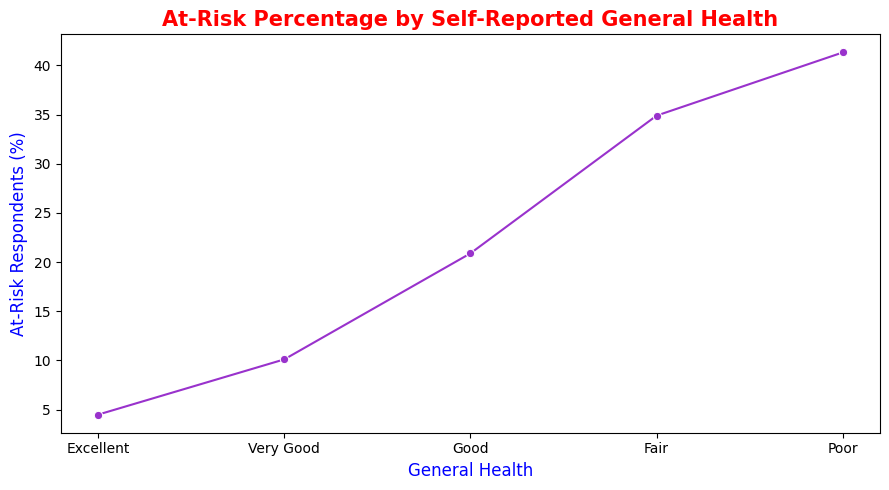

In [53]:
health_labels = {
    1: "Excellent",
    2: "Very Good",
    3: "Good",
    4: "Fair",
    5: "Poor"
}

genhlth_risk = (
    df.groupby("GenHlth")["Health_Status"]
    .agg(AtRisk_Rate="mean", Count="size")
    .reset_index()
)

genhlth_risk["AtRisk_Percent"] = genhlth_risk["AtRisk_Rate"] * 100
genhlth_risk = genhlth_risk.sort_values("GenHlth")

plt.figure(figsize=(9, 5))

sns.lineplot(
    data=genhlth_risk,
    x="GenHlth",
    y="AtRisk_Percent",
    marker="o",
    sort=True,
    color="darkorchid"
)

plt.xticks(
    ticks=[1, 2, 3, 4, 5],
    labels=[health_labels[i] for i in range(1, 6)]
)

plt.title(
    "At-Risk Percentage by Self-Reported General Health",
    fontsize=15, fontweight="bold", color="red"
)
plt.xlabel("General Health", fontsize=12, color="blue")
plt.ylabel("At-Risk Respondents (%)", fontsize=12, color="blue")

plt.tight_layout()
plt.savefig(
    ASSET_DIR / "AtRisk_by_General_Health.png",
    dpi=300, bbox_inches="tight"
)
plt.show()

# ***Compare 2015 and 2021***

,No diabetes (%),Prediabetes (%),Diabetes (%),Binary positive target (%)
Year,,,,
2015,82.71,2.01,15.27,17.29
2021,82.55,2.51,14.94,17.45


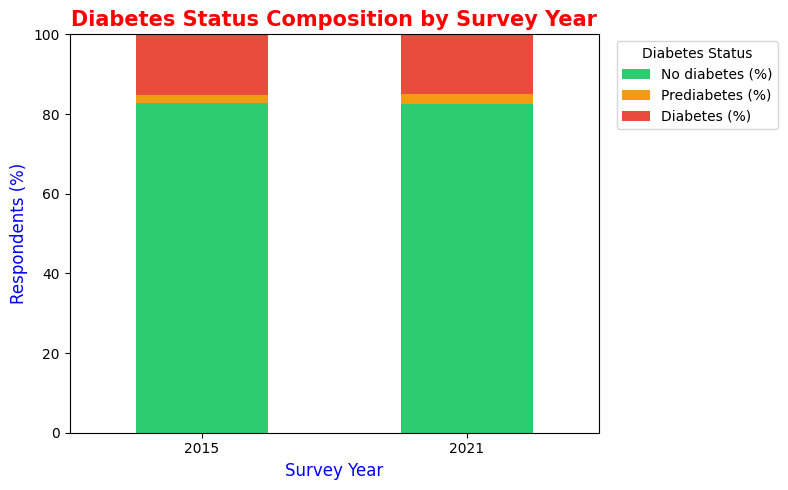

In [54]:
# Three-class composition within each survey year.
year_class_pct = pd.crosstab(
    df["Year"],
    df["Diabetes_012"],
    normalize="index"
).reindex(columns=[0.0, 1.0, 2.0], fill_value=0) * 100

year_class_pct.columns = [
    "No diabetes (%)",
    "Prediabetes (%)",
    "Diabetes (%)"
]

# Add the binary positive-target rate as a separate table column.
year_binary_pct = (
    df.groupby("Year")["Health_Status"].mean() * 100
)

year_summary = year_class_pct.copy()
year_summary["Binary positive target (%)"] = (
    year_binary_pct.reindex(year_summary.index)
)

display(year_summary.round(2))

# Plot the three mutually exclusive classes only.
plt.figure(figsize=(8, 5))

ax = year_class_pct.plot(
    kind="bar",
    stacked=True,
    ax=plt.gca(),
    color=["#2ecc71", "#f39c12", "#e74c3c"]
)

ax.set_ylim(0, 100)

plt.title(
    "Diabetes Status Composition by Survey Year",
    fontsize=15,
    fontweight="bold",
    color="red"
)
plt.xlabel("Survey Year", fontsize=12, color="blue")
plt.ylabel("Respondents (%)", fontsize=12, color="blue")
plt.xticks(rotation=0)
plt.legend(
    title="Diabetes Status",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.savefig(
    ASSET_DIR / "Health_Status_by_Year.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# At-Risk percentage by age and income

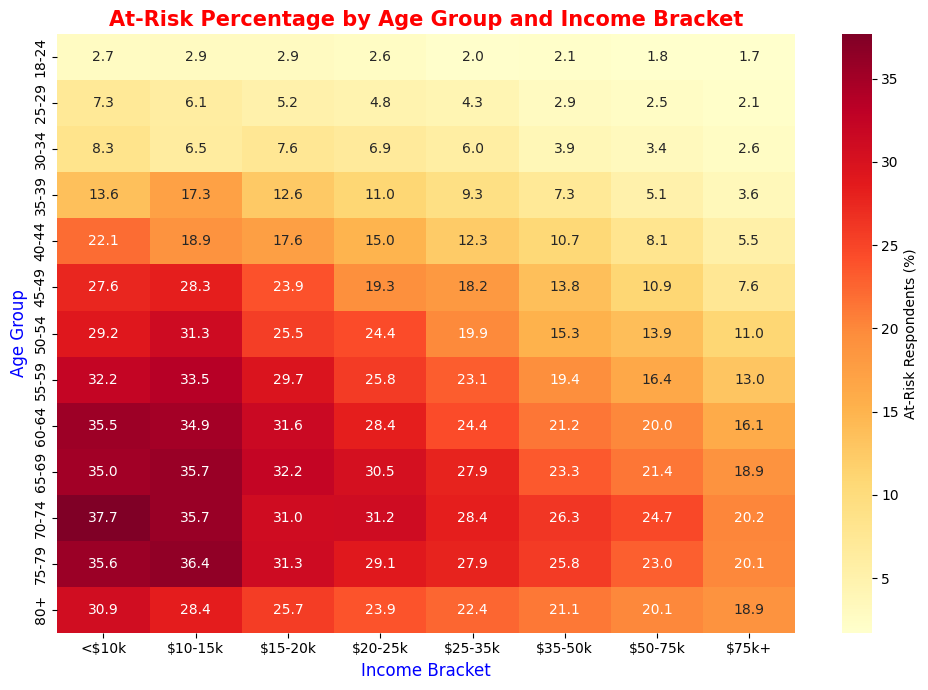

In [55]:
age_mapping = {
    1: "18-24", 2: "25-29", 3: "30-34",
    4: "35-39", 5: "40-44", 6: "45-49",
    7: "50-54", 8: "55-59", 9: "60-64",
    10: "65-69", 11: "70-74",
    12: "75-79", 13: "80+"
}

income_mapping = {
    1: "<$10k",
    2: "$10-15k",
    3: "$15-20k",
    4: "$20-25k",
    5: "$25-35k",
    6: "$35-50k",
    7: "$50-75k",
    8: "$75k+"
}

age_income_risk = (
    df.pivot_table(
        index="Age",
        columns="Income_Harmonized",
        values="Health_Status",
        aggfunc="mean"
    ) * 100
)

age_income_risk = age_income_risk.reindex(
    index=list(age_mapping.keys()),
    columns=list(income_mapping.keys())
)

# Apply readable labels to the heatmap axes.
age_income_risk.index = [
    age_mapping[i] for i in age_income_risk.index
]
age_income_risk.columns = [
    income_mapping[i] for i in age_income_risk.columns
]

plt.figure(figsize=(10, 7))

sns.heatmap(
    age_income_risk,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    cbar_kws={"label": "At-Risk Respondents (%)"}
)

plt.title(
    "At-Risk Percentage by Age Group and Income Bracket",
    fontsize=15,
    fontweight="bold",
    color="red"
)
plt.xlabel("Income Bracket", fontsize=12, color="blue")
plt.ylabel("Age Group", fontsize=12, color="blue")

plt.tight_layout()
plt.savefig(
    ASSET_DIR / "AtRisk_by_Age_Income.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Combined health risk profiles

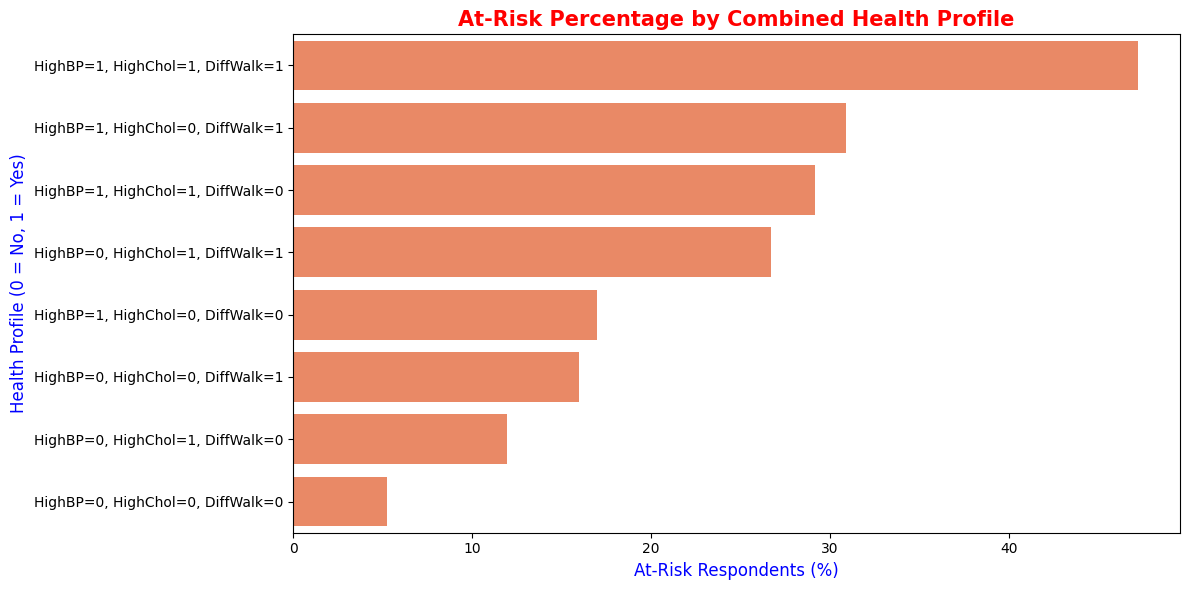

In [56]:
profile = (
    df.groupby(["HighBP", "HighChol", "DiffWalk"])["Health_Status"]
    .agg(AtRisk_Rate="mean", Count="size")
    .reset_index()
)

profile["AtRisk_Percent"] = profile["AtRisk_Rate"] * 100

profile["Profile"] = profile.apply(
    lambda row: (
        f"HighBP={int(row['HighBP'])}, "
        f"HighChol={int(row['HighChol'])}, "
        f"DiffWalk={int(row['DiffWalk'])}"
    ),
    axis=1
)

profile = profile[profile["Count"] >= 100]
profile = profile.sort_values("AtRisk_Percent", ascending=False)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=profile,
    x="AtRisk_Percent",
    y="Profile",
    color="coral"
)

plt.title(
    "At-Risk Percentage by Combined Health Profile",
    fontsize=15, fontweight="bold", color="red"
)
plt.xlabel("At-Risk Respondents (%)", fontsize=12, color="blue")
plt.ylabel("Health Profile (0 = No, 1 = Yes)", fontsize=12, color="blue")

plt.tight_layout()
plt.savefig(
    ASSET_DIR / "AtRisk_by_Combined_Profile.png",
    dpi=300, bbox_inches="tight"
)
plt.show()

# Mutual information with Health_Status

,Feature,MI_Score
13,GenHlth,0.0395
0,HighBP,0.0337
18,Age,0.0235
3,BMI,0.0224
1,HighChol,0.0205
16,DiffWalk,0.0191
6,HeartDiseaseorAttack,0.0118
20,Income_Harmonized,0.0104
15,PhysHlth,0.0097
7,PhysActivity,0.0066


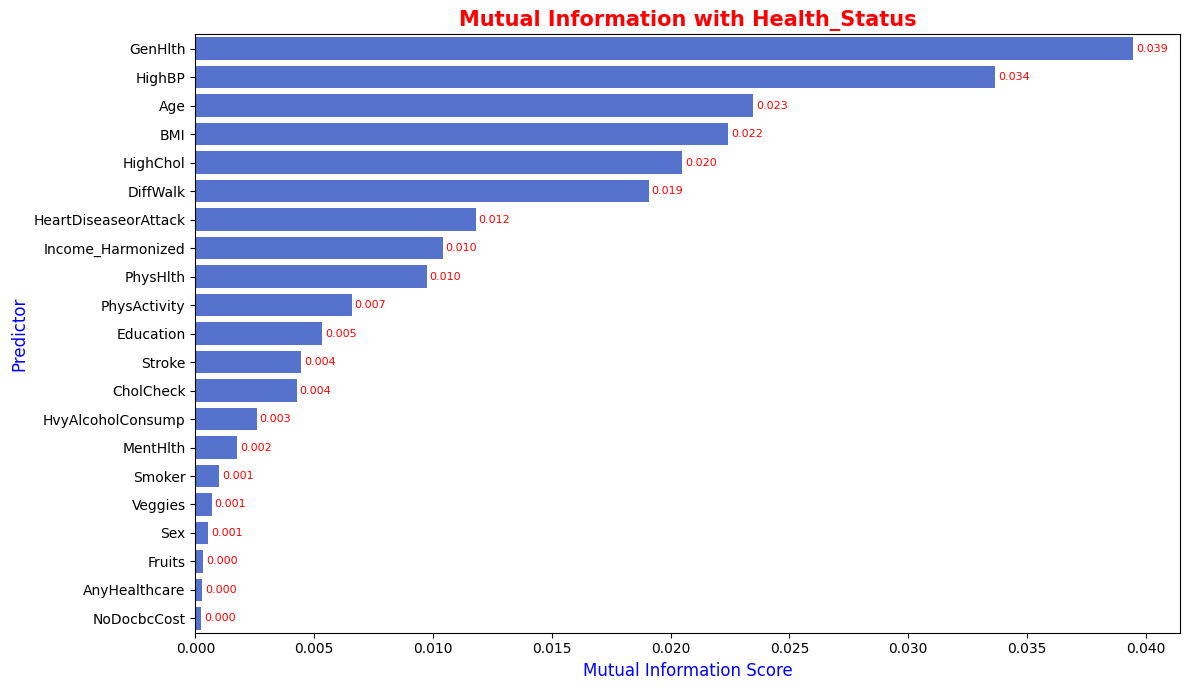

In [57]:
features = [
    "HighBP", "HighChol", "CholCheck", "BMI", "Smoker",
    "Stroke", "HeartDiseaseorAttack", "PhysActivity",
    "Fruits", "Veggies", "HvyAlcoholConsump",
    "AnyHealthcare", "NoDocbcCost", "GenHlth",
    "MentHlth", "PhysHlth", "DiffWalk", "Sex",
    "Age", "Education", "Income_Harmonized"
]

target_col = "Health_Status"

mi_sample = df[features + [target_col]].sample(
    n=min(100000, len(df)),
    random_state=42
)

X = mi_sample[features]
y = mi_sample[target_col].astype(int)

# Preserve the estimation method underlying the report's scores.
# These three features use the continuous-feature estimator.
continuous_features = {"BMI", "MentHlth", "PhysHlth"}

discrete_features = [
    feature not in continuous_features
    for feature in features
]

mi_scores = mutual_info_classif(
    X,
    y,
    discrete_features=discrete_features,
    random_state=42
)

mi_df = pd.DataFrame({
    "Feature": features,
    "MI_Score": mi_scores
}).sort_values(
    "MI_Score",
    ascending=False
)

display(mi_df.head(10).round(4))

plt.figure(figsize=(12, 7))

ax = sns.barplot(
    data=mi_df,
    x="MI_Score",
    y="Feature",
    color="royalblue"
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        padding=2,
        color="red",
        fontsize=8
    )

plt.title(
    "Mutual Information with Health_Status",
    fontsize=15,
    fontweight="bold",
    color="red"
)
plt.xlabel("Mutual Information Score", fontsize=12, color="blue")
plt.ylabel("Predictor", fontsize=12, color="blue")

plt.tight_layout()
plt.savefig(
    ASSET_DIR / "Mutual_Information_Health_Status.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Predictor-only correlation heatmap

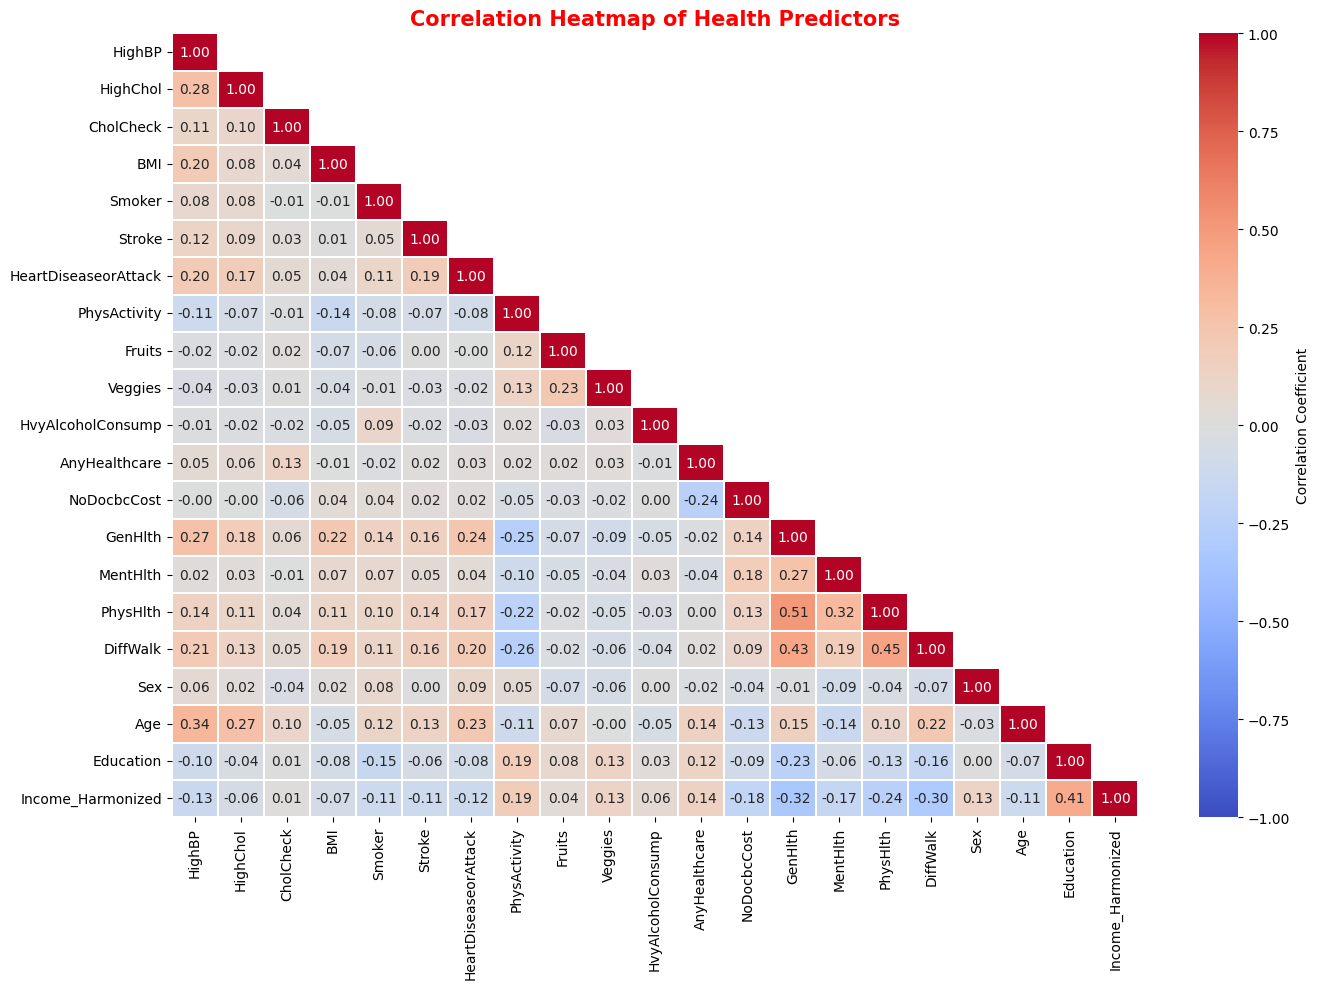

In [58]:
correlation_features = [
    "HighBP", "HighChol", "CholCheck", "BMI", "Smoker",
    "Stroke", "HeartDiseaseorAttack", "PhysActivity",
    "Fruits", "Veggies", "HvyAlcoholConsump",
    "AnyHealthcare", "NoDocbcCost", "GenHlth",
    "MentHlth", "PhysHlth", "DiffWalk", "Sex",
    "Age", "Education", "Income_Harmonized"
]

correlation_matrix = df[correlation_features].corr(
    numeric_only=True
)

mask = np.triu(
    np.ones_like(correlation_matrix, dtype=bool),
    k=1
)

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.3,
    cbar_kws={"label": "Correlation Coefficient"}
)

plt.title(
    "Correlation Heatmap of Health Predictors",
    fontsize=15,
    fontweight="bold",
    color="red"
)

plt.tight_layout()
plt.savefig(
    ASSET_DIR / "Correlation_Heatmap_Predictors.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Pre-Calculated Assets & Metrics

In [59]:
# Ensure MODEL_DIR exists
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Pre-calculate key metrics and statistics for the home page
metrics = {
    "total_records": int(len(df)),
    "total_features": int(df.shape[1]),
    "years_covered": [int(y) for y in sorted(df["Year"].unique())],
    "health_status_counts": {
        str(k): int(v)
        for k, v in df["Health_Status_Label"].value_counts().items()
    },
    "health_status_percentages": {
        str(k): float(v)
        for k, v in (
            df["Health_Status_Label"].value_counts(normalize=True) * 100
        ).items()
    },
    "prevalence": {
        "high_bp_pct": float(df["HighBP"].mean() * 100),
        "high_chol_pct": float(df["HighChol"].mean() * 100),
        "heart_disease_pct": float(df["HeartDiseaseorAttack"].mean() * 100),
        "avg_bmi": float(df["BMI"].mean()),
        "phys_activity_pct": float(df["PhysActivity"].mean() * 100),
    },
}

# Save metrics to JSON in the Models directory
metrics_path = MODEL_DIR / "home_metrics.json"
with open(metrics_path, "w") as f:
  json.dump(metrics, f, indent=4)

print(f"Successfully pre-calculated and saved home page metrics to: {metrics_path}")

Successfully pre-calculated and saved home page metrics to: D:\ANN- health-risk-prediction-project\Models\home_metrics.json
